
**Práctica 2: Aplicaciones del Aprendizaje Automático**

**Autor:** Ana Cascante
**Tecnologías:** Python, scikit-learn, PCA, K-Means, Clustering Jerárquico

**Segmentación de Clientes de E-Commerce mediante Clusterización y PCA**

**1. Descripción del Caso de Uso**

**1.1 Contexto del Problema**

En el mundo del comercio electrónico, comprender el comportamiento de los clientes es fundamental para el éxito del negocio. Las empresas online manejan grandes volúmenes de transacciones diariamente, generando una cantidad masiva de datos sobre patrones de compra, preferencias y comportamientos de los usuarios.

El desafío principal es identificar grupos de clientes con comportamientos similares para poder:
- Personalizar estrategias de marketing
- Optimizar campañas publicitarias
- Mejorar la retención de clientes
- Aumentar el valor del tiempo de vida del cliente (Customer Lifetime Value)
- Desarrollar productos y servicios adaptados a cada segmento

**1.2 Objetivo**

**Objetivo Principal:** Segmentar la base de clientes de un e-commerce en grupos homogéneos según su comportamiento de compra, utilizando técnicas de Clusterización y Análisis de Componentes Principales (PCA).

**Objetivos Específicos:**
1. Identificar patrones de comportamiento de compra mediante análisis RFM (Recency, Frequency, Monetary)
2. Reducir la dimensionalidad de los datos mediante PCA para facilitar la visualización y el análisis
3. Aplicar algoritmos de clustering para segmentar a los clientes
4. Caracterizar cada segmento de clientes identificado
5. Proporcionar insights accionables para el equipo de marketing

**1.3 Justificación del Uso de Aprendizaje Automático**

El Aprendizaje No Supervisado es la técnica ideal para este problema por las siguientes razones:

**¿Por qué Clustering?**
- No tenemos etiquetas previas: No sabemos de antemano cuántos tipos de clientes existen ni cómo clasificarlos
- Descubrimiento de patrones ocultos: Los algoritmos de clustering pueden identificar grupos naturales en los datos que no son evidentes a simple vista
- Escalabilidad: Puede procesar miles de clientes automáticamente, algo imposible de hacer manualmente
- Objetividad: Elimina sesgos humanos en la clasificación de clientes

**¿Por qué PCA?**
- Reducción de dimensionalidad: Simplifica el dataset manteniendo la información más relevante
- Visualización: Permite representar clientes en 2D o 3D para interpretación visual
- Eliminación de multicolinealidad: Reduce correlaciones entre variables que pueden afectar el clustering
- Mejora del rendimiento: Reduce el coste computacional de los algoritmos de clustering

**Ventajas sobre Métodos Tradicionales:**
- Automatización: Procesa grandes volúmenes de datos sin intervención manual
- Adaptabilidad: Se actualiza fácilmente con nuevos datos
- Precisión: Identifica segmentos más precisos que la segmentación demográfica tradicional
- Escalabilidad: Puede aplicarse a millones de clientes sin pérdida de eficiencia

**2. Dataset**

**2.1 Origen del Dataset**

**Fuente:** Kaggle - Online Retail Dataset  
**URL:** https://www.kaggle.com/datasets/lakshmi25npathi/online-retail-dataset  
**Autor:** Lakshmi Narayana Pudipeddi  
**Licencia:** Database Contents License (DbCL) v1.0

Este dataset contiene transacciones de un comercio minorista online con sede en el Reino Unido, registradas entre **01/12/2010 y 09/12/2011**. La empresa se especializa en regalos únicos para todas las ocasiones, y muchos de sus clientes son mayoristas.

**2.2 Descripción de las Variables**

El dataset original contiene 8 variables:

| Variable | Tipo | Descripción |
|----------|------|-------------|
| InvoiceNo | String | Número de factura único de 6 dígitos. Si empieza con 'C', indica cancelación |
| StockCode | String | Código único del producto (5 dígitos) |
| Description | String | Nombre/descripción del producto |
| Quantity | Integer | Cantidad de productos por transacción |
| InvoiceDate | DateTime | Fecha y hora de la transacción |
| UnitPrice | Float | Precio unitario del producto en libras esterlinas (£) |
| CustomerID | Float | Identificador único del cliente (5 dígitos) |
| Country | String | País de residencia del cliente |

**2.3 Tamaño e Información Relevante**

- Número de registros: ~541,909 transacciones
- Período temporal: 12 meses (Diciembre 2010 - Diciembre 2011)
- Número de clientes únicos: ~4,372 clientes
- Número de productos únicos: ~3,684 productos
- Países representados: 38 países

**Características importantes:**
- Presencia de valores nulos en CustomerID (~25% de las transacciones)
- Transacciones canceladas (InvoiceNo que empiezan con 'C')
- Valores negativos en Quantity (devoluciones)
- Valores de precio igual a 0

**2.4 Procesamiento Aplicado**

El procesamiento del dataset incluirá los siguientes pasos:

**Limpieza de Datos:**
1. Eliminación de nulos: Remover transacciones sin CustomerID
2. Filtrado de cancelaciones: Eliminar facturas que empiezan con 'C'
3. Valores inválidos: Eliminar cantidades y precios negativos o igual a 0
4. Duplicados: Identificar y eliminar registros duplicados

**Ingeniería de Características (Feature Engineering):**
Creación de métricas de comportamiento del cliente basadas en análisis RFM:

- Recency (R): Días desde la última compra
- Frequency (F): Número total de compras realizadas
- Monetary (M): Valor total gastado por el cliente

**Métricas adicionales:**
- Valor promedio de orden (Average Order Value - AOV)
- Número total de productos comprados
- Diversidad de productos (número de productos únicos)
- Tasa de cancelación (si aplica)

**Normalización:**
- Aplicación de StandardScaler o MinMaxScaler para estandarizar las características
- Esto es crucial para algoritmos de clustering sensibles a la escala (K-Means, PCA)

**Reducción de Dimensionalidad:**
- Aplicación de PCA para reducir el número de características manteniendo el 95% de la varianza explicada

**3. Metodología**

**3.1 Técnicas Utilizadas**

**3.1.1 Análisis de Componentes Principales (PCA)**

**Descripción:**  
PCA es una técnica de reducción de dimensionalidad que transforma un conjunto de variables correlacionadas en un nuevo conjunto de variables no correlacionadas llamadas componentes principales. Estos componentes se ordenan por la cantidad de varianza que explican del dataset original.

**¿Cómo funciona?**
1. Calcula la matriz de covarianza de las características estandarizadas
2. Calcula los valores propios (eigenvalues) y vectores propios (eigenvectors)
3. Ordena los componentes principales por varianza explicada
4. Selecciona los K primeros componentes que explican la mayor varianza

**Ventajas:**
- Reduce dimensionalidad manteniendo información relevante
- Elimina multicolinealidad entre variables
- Facilita visualización en 2D/3D
- Mejora rendimiento de algoritmos de clustering

**3.1.2 K-Means Clustering**

**Descripción:**  
K-Means es un algoritmo de clustering particional que divide los datos en K grupos (clusters) minimizando la varianza intra-cluster. Cada cluster está representado por su centroide (promedio de todos los puntos del cluster).

**Tipo de Algoritmo:**
1. Inicializa K centroides aleatoriamente
2. Asigna cada punto al centroide más cercano
3. Recalcula los centroides como el promedio de los puntos asignados
4. Repite pasos 2-3 hasta convergencia

**Ventajas:**
- Simple y eficiente computacionalmente
- Funciona bien con clusters esféricos
- Escalable a grandes datasets

**Limitaciones:**
- Requiere especificar K a priori
- Sensible a outliers y a la inicialización
- Asume clusters de forma esférica

**3.1.3 Clustering Jerárquico (Hierarchical Clustering)**

**Descripción:**  
Crea una jerarquía de clusters mediante un enfoque aglomerativo (bottom-up) o divisivo (top-down). El resultado se visualiza mediante un dendrograma.

**Algoritmo Aglomerativo:**
1. Cada punto comienza como un cluster individual
2. Fusiona los dos clusters más cercanos
3. Repite hasta tener un solo cluster
4. Corta el dendrograma a la altura deseada para obtener K clusters

**Ventajas:**
- No requiere especificar K a priori
- Produce un dendrograma interpretable
- Puede capturar clusters de formas irregulares

**Limitaciones:**
- Computacionalmente costoso (O(n³))
- No escalable a datasets muy grandes
- Sensible a ruido y outliers

**3.1.4 DBSCAN (Density-Based Spatial Clustering)**

**Descripción:**  
DBSCAN agrupa puntos que están densamente conectados y marca como outliers los puntos en regiones de baja densidad.

**Parámetros:**
- eps (ε): Radio de vecindad
- min_samples: Número mínimo de puntos para formar un cluster denso

**Ventajas:**
- No requiere especificar K
- Detecta outliers automáticamente
- Puede encontrar clusters de formas arbitrarias

**Limitaciones:**
- Sensible a los parámetros eps y min_samples
- Dificultad con clusters de densidades variables

**3.2 Parámetros e Hiper-parámetros**

 **PCA:**
- n_components: Número de componentes principales a retener
  - Se determina mediante análisis de varianza explicada acumulada
  - Objetivo: Retener al menos 85-95% de la varianza
  - En este proyecto: Se evaluará automáticamente

**K-Means:**
- n_clusters (K): Número de clusters
  - Se determina mediante Método del Codo (Elbow Method)
  - Se valida con Silhouette Score
  - Rango explorado: 2-10 clusters
- init: Método de inicialización = 'k-means++'
  - Mejora la convergencia y evita mínimos locales
- n_init: Número de inicializaciones = 10
  - Ejecuta el algoritmo 10 veces y selecciona el mejor resultado
- max_iter: Iteraciones máximas = 300
- random_state: Semilla aleatoria = 42 (reproducibilidad)

 **Clustering Jerárquico:**
- n_clusters: Número de clusters (determinado por dendrograma)
- linkage: Método de enlace = 'ward'
  - Minimiza la varianza dentro de los clusters
  - Alternativas: 'complete', 'average', 'single'
- affinity: Métrica de distancia = 'euclidean'

**DBSCAN:**
- eps: Radio de vecindad (se determinará mediante análisis de k-distancia)
- min_samples: Mínimo de puntos = 2 * dimensionalidad
- metric: Distancia euclidiana

**3.3 Justificación de Decisiones Técnicas**

**¿Por qué usar PCA antes de Clustering?**
1. Reducción de ruido: Elimina características menos informativas
2. Mejora de rendimiento: Reduce complejidad computacional
3. Visualización: Permite representar clusters en 2D/3D
4. Eliminación de correlaciones: Componentes principales son ortogonales

**¿Por qué K-Means como algoritmo principal?**
1. Eficiencia: Rápido incluso con miles de clientes
2. Simplicidad: Fácil de interpretar y explicar al negocio
3. Clusters compactos: Ideal para segmentación de clientes (grupos homogéneos)

**¿Por qué comparar múltiples algoritmos?**
1. Validación cruzada: Confirmar consistencia de los resultados
2. Robustez: Diferentes algoritmos capturan diferentes patrones
3. Detección de outliers: DBSCAN identifica clientes atípicos

**¿Por qué análisis RFM?**
1. Estándar de la industria: Ampliamente utilizado en marketing
2. Interpretabilidad: Métricas con significado empresarial claro
3. Predictivo: RFM correlaciona fuertemente con valor futuro del cliente

**Normalización:**
- StandardScaler: Se usa porque K-Means es sensible a la escala
- Garantiza que todas las características tengan la misma importancia
- Evita que características con mayor magnitud dominen el clustering

**Implementación del Proyecto**


**Paso 1: Importación de Librerías**

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np
from datetime import datetime

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist

# Métricas
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import silhouette_samples

# Descarga de datos
import kagglehub

# Configuración
import warnings
warnings.filterwarnings('ignore')

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Semilla para reproducibilidad
np.random.seed(42)

print("✓ Todas las librerías importadas correctamente")
print(f"Versión de pandas: {pd.__version__}")
print(f"Versión de numpy: {np.__version__}")

✓ Todas las librerías importadas correctamente
Versión de pandas: 2.3.3
Versión de numpy: 2.4.1


C:\Users\Ana\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Paso 2: Descarga y Carga del Dataset**

In [2]:
# Convertir Excel a CSV
#df_temp = pd.read_excel('online_retail_II.xlsx')
#df_temp.to_csv('online_retail_II.csv', index=False, encoding='utf-8')
#print("✓ Archivo convertido a CSV")

In [3]:
# Cargar el dataset desde archivo local
# El archivo está en la misma carpeta que este notebook
file_path = 'online_retail_II.csv'

print(f"Cargando dataset desde: {file_path}")

# Cargar el dataset desde archivo CSV
df_raw = pd.read_csv(file_path)

print(f"\n✓ Dataset cargado exitosamente")
print(f"Forma del dataset: {df_raw.shape}")
print(f"Columnas: {df_raw.columns.tolist()}")

Cargando dataset desde: online_retail_II.csv

✓ Dataset cargado exitosamente
Forma del dataset: (525461, 8)
Columnas: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']


**Paso 3: Exploración Inicial de Datos**

In [4]:
# Información general del dataset
print("="*80)
print("INFORMACIÓN GENERAL DEL DATASET")
print("="*80)
print(f"\nDimensiones: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

# Mostrar las columnas disponibles
print(f"\nColumnas disponibles en el dataset:")
print(df_raw.columns.tolist())

print(f"\nPrimeras 5 filas:")
display(df_raw.head())

print("\n" + "="*80)
print("TIPOS DE DATOS Y VALORES NULOS")
print("="*80)
df_info = pd.DataFrame({
    'Tipo': df_raw.dtypes,
    'Nulos': df_raw.isnull().sum(),
    '% Nulos': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Únicos': df_raw.nunique()
})
display(df_info)

print("\n" + "="*80)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("="*80)
display(df_raw.describe())

# Información adicional
print("\n" + "="*80)
print("INFORMACIÓN ADICIONAL")
print("="*80)
print(f"Clientes únicos: {df_raw['CustomerID'].nunique():,}")
print(f"Productos únicos: {df_raw['StockCode'].nunique():,}")
print(f"Países: {df_raw['Country'].nunique()}")
print(f"Facturas: {df_raw['Invoice'].nunique():,}")
print(f"\nFacturas canceladas (comienzan con 'C'): {df_raw[df_raw['Invoice'].astype(str).str.startswith('C', na=False)].shape[0]:,}")
print(f"Transacciones con cantidad negativa: {df_raw[df_raw['Quantity'] < 0].shape[0]:,}")
print(f"Transacciones con precio = 0: {df_raw[df_raw['Price'] == 0].shape[0]:,}")

INFORMACIÓN GENERAL DEL DATASET

Dimensiones: 525,461 filas × 8 columnas

Columnas disponibles en el dataset:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']

Primeras 5 filas:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



TIPOS DE DATOS Y VALORES NULOS


,Tipo,Nulos,% Nulos,Únicos
Invoice,object,0,0.00,28816
StockCode,object,0,0.00,4632
Description,object,2928,0.56,4681
Quantity,int64,0,0.00,825
InvoiceDate,object,0,0.00,25296
Price,float64,0,0.00,1606
CustomerID,float64,107927,20.54,4383
Country,object,0,0.00,40



ESTADÍSTICAS DESCRIPTIVAS


,Quantity,Price,CustomerID
count,525461.000000,525461.000000,417534.000000
mean,10.337667,4.688834,15360.645478
std,107.424110,146.126914,1680.811316
min,-9600.000000,-53594.360000,12346.000000
25%,1.000000,1.250000,13983.000000
50%,3.000000,2.100000,15311.000000
75%,10.000000,4.210000,16799.000000
max,19152.000000,25111.090000,18287.000000



INFORMACIÓN ADICIONAL
Clientes únicos: 4,383
Productos únicos: 4,632
Países: 40
Facturas: 28,816

Facturas canceladas (comienzan con 'C'): 10,206
Transacciones con cantidad negativa: 12,326
Transacciones con precio = 0: 3,687


**Paso 4: Limpieza y Preprocesamiento de Datos**

In [5]:
# Crear una copia para el procesamiento
df = df_raw.copy()

print("="*80)
print("LIMPIEZA DE DATOS")
print("="*80)

# Registros iniciales
print(f"\n1. Registros iniciales: {len(df):,}")

# Eliminar filas con Customer ID nulo (no podemos hacer RFM sin cliente)
df = df[df['CustomerID'].notna()]
print(f"2. Después de eliminar Customer ID nulos: {len(df):,} ({len(df)/len(df_raw)*100:.1f}% restante)")

# Eliminar facturas canceladas (que comienzan con 'C')
df = df[~df['Invoice'].astype(str).str.startswith('C')]
print(f"3. Después de eliminar cancelaciones: {len(df):,}")

# Eliminar transacciones con cantidad <= 0
df = df[df['Quantity'] > 0]
print(f"4. Después de eliminar cantidades ≤ 0: {len(df):,}")

# Eliminar transacciones con precio <= 0
df = df[df['Price'] > 0]
print(f"5. Después de eliminar precios ≤ 0: {len(df):,}")

# Eliminar duplicados
duplicados_antes = df.duplicated().sum()
df = df.drop_duplicates()
print(f"6. Duplicados eliminados: {duplicados_antes:,}")
print(f"   Dataset final: {len(df):,} transacciones")

# Convertir InvoiceDate a datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Crear columna de TotalPrice (cantidad * precio unitario)
df['TotalPrice'] = df['Quantity'] * df['Price']

print(f"\n✓ Limpieza completada")
print(f"✓ Clientes únicos después de limpieza: {df['CustomerID'].nunique():,}")
print(f"✓ Período de datos: {df['InvoiceDate'].min().date()} a {df['InvoiceDate'].max().date()}")

# Mostrar dataset limpio
display(df.head(10))

LIMPIEZA DE DATOS

1. Registros iniciales: 525,461
2. Después de eliminar Customer ID nulos: 417,534 (79.5% restante)
3. Después de eliminar cancelaciones: 407,695
4. Después de eliminar cantidades ≤ 0: 407,695
5. Después de eliminar precios ≤ 0: 407,664
6. Duplicados eliminados: 6,748
   Dataset final: 400,916 transacciones

✓ Limpieza completada
✓ Clientes únicos después de limpieza: 4,312
✓ Período de datos: 2009-12-01 a 2010-12-09


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,39.6
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,59.5
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom,30.6
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom,45.0


**Paso 5: Ingeniería de Características - Análisis RFM**

In [6]:
"""
RFM Analysis:
- Recency (R): Días desde la última compra (menor es mejor)
- Frequency (F): Número de compras (mayor es mejor)
- Monetary (M): Valor total gastado (mayor es mejor)
"""

print("="*80)
print("CREACIÓN DE CARACTERÍSTICAS RFM")
print("="*80)

# Definir fecha de referencia (1 día después de la última transacción)
fecha_referencia = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"\nFecha de referencia para cálculo de Recency: {fecha_referencia.date()}")

# Agrupar por Customer ID y calcular métricas
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (fecha_referencia - x.max()).days,  # Recency
    'Invoice': 'nunique',  # Frequency (número de compras únicas)
    'TotalPrice': 'sum'  # Monetary (valor total gastado)
}).reset_index()

# Renombrar columnas
rfm.columns = ['Customer_ID', 'InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary']

# Métricas adicionales
print("\n" + "="*80)
print("MÉTRICAS ADICIONALES")
print("="*80)

# Average Order Value (AOV)
rfm['AOV'] = rfm['TotalPrice_Monetary'] / rfm['Invoice_Frequency']

# Número total de productos comprados por cliente
productos_por_cliente = df.groupby('CustomerID')['Quantity'].sum().reset_index()
productos_por_cliente.columns = ['Customer_ID', 'TotalProducts']
rfm = rfm.merge(productos_por_cliente, on='Customer_ID', how='left')

# Diversidad de productos (número de productos únicos comprados)
diversidad_productos = df.groupby('CustomerID')['StockCode'].nunique().reset_index()
diversidad_productos.columns = ['Customer_ID', 'UniqueProducts']
rfm = rfm.merge(diversidad_productos, on='Customer_ID', how='left')

# Productos promedio por orden
rfm['AvgProductsPerOrder'] = rfm['TotalProducts'] / rfm['Invoice_Frequency']

print(f"\n✓ Características RFM creadas para {len(rfm):,} clientes")
print(f"\nCaracterísticas finales:")
print(rfm.columns.tolist())

print("\n" + "="*80)
print("ESTADÍSTICAS RFM")
print("="*80)
display(rfm.describe())

# Mostrar primeros clientes
print("\n" + "="*80)
print("PRIMEROS 10 CLIENTES")
print("="*80)
display(rfm.head(10))

CREACIÓN DE CARACTERÍSTICAS RFM

Fecha de referencia para cálculo de Recency: 2010-12-10

MÉTRICAS ADICIONALES

✓ Características RFM creadas para 4,312 clientes

Características finales:
['Customer_ID', 'InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV', 'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder']

ESTADÍSTICAS RFM


,Customer_ID,InvoiceDate_Recency,Invoice_Frequency,TotalPrice_Monetary,AOV,TotalProducts,UniqueProducts,AvgProductsPerOrder
count,4312.000000,4312.000000,4312.000000,4312.000000,4312.000000,4312.000000,4312.000000,4312.000000
mean,15349.290353,91.171846,4.455705,2040.406712,376.373364,1280.050557,63.646104,254.623161
std,1701.200176,96.860633,8.170213,8911.755977,492.357455,6457.926351,85.757966,1554.076374
min,12346.000000,1.000000,1.000000,2.950000,2.950000,1.000000,1.000000,1.000000
25%,13882.500000,18.000000,1.000000,307.187500,179.490000,156.000000,17.000000,89.000000
50%,15350.500000,53.000000,2.000000,701.615000,285.048333,380.000000,38.000000,150.892045
75%,16834.250000,136.000000,5.000000,1714.932500,421.483750,992.000000,79.250000,255.050000
max,18287.000000,374.000000,205.000000,349164.350000,11880.840000,220600.000000,1741.000000,87167.000000



PRIMEROS 10 CLIENTES


,Customer_ID,InvoiceDate_Recency,Invoice_Frequency,TotalPrice_Monetary,AOV,TotalProducts,UniqueProducts,AvgProductsPerOrder
0,12346.0,165,11,372.86,33.896364,70,26,6.363636
1,12347.0,3,2,1323.32,661.660000,828,70,414.000000
2,12348.0,74,1,222.16,222.160000,373,20,373.000000
3,12349.0,43,3,2671.14,890.380000,993,90,331.000000
4,12351.0,11,1,300.93,300.930000,261,21,261.000000
5,12352.0,11,2,343.80,171.900000,188,18,94.000000
6,12353.0,44,1,317.76,317.760000,192,20,192.000000
7,12355.0,203,1,488.21,488.210000,303,22,303.000000
8,12356.0,16,3,3560.30,1186.766667,1825,68,608.333333
9,12357.0,24,2,12079.99,6039.995000,3879,165,1939.500000


**Paso 6: Análisis Exploratorio de Datos (EDA)**

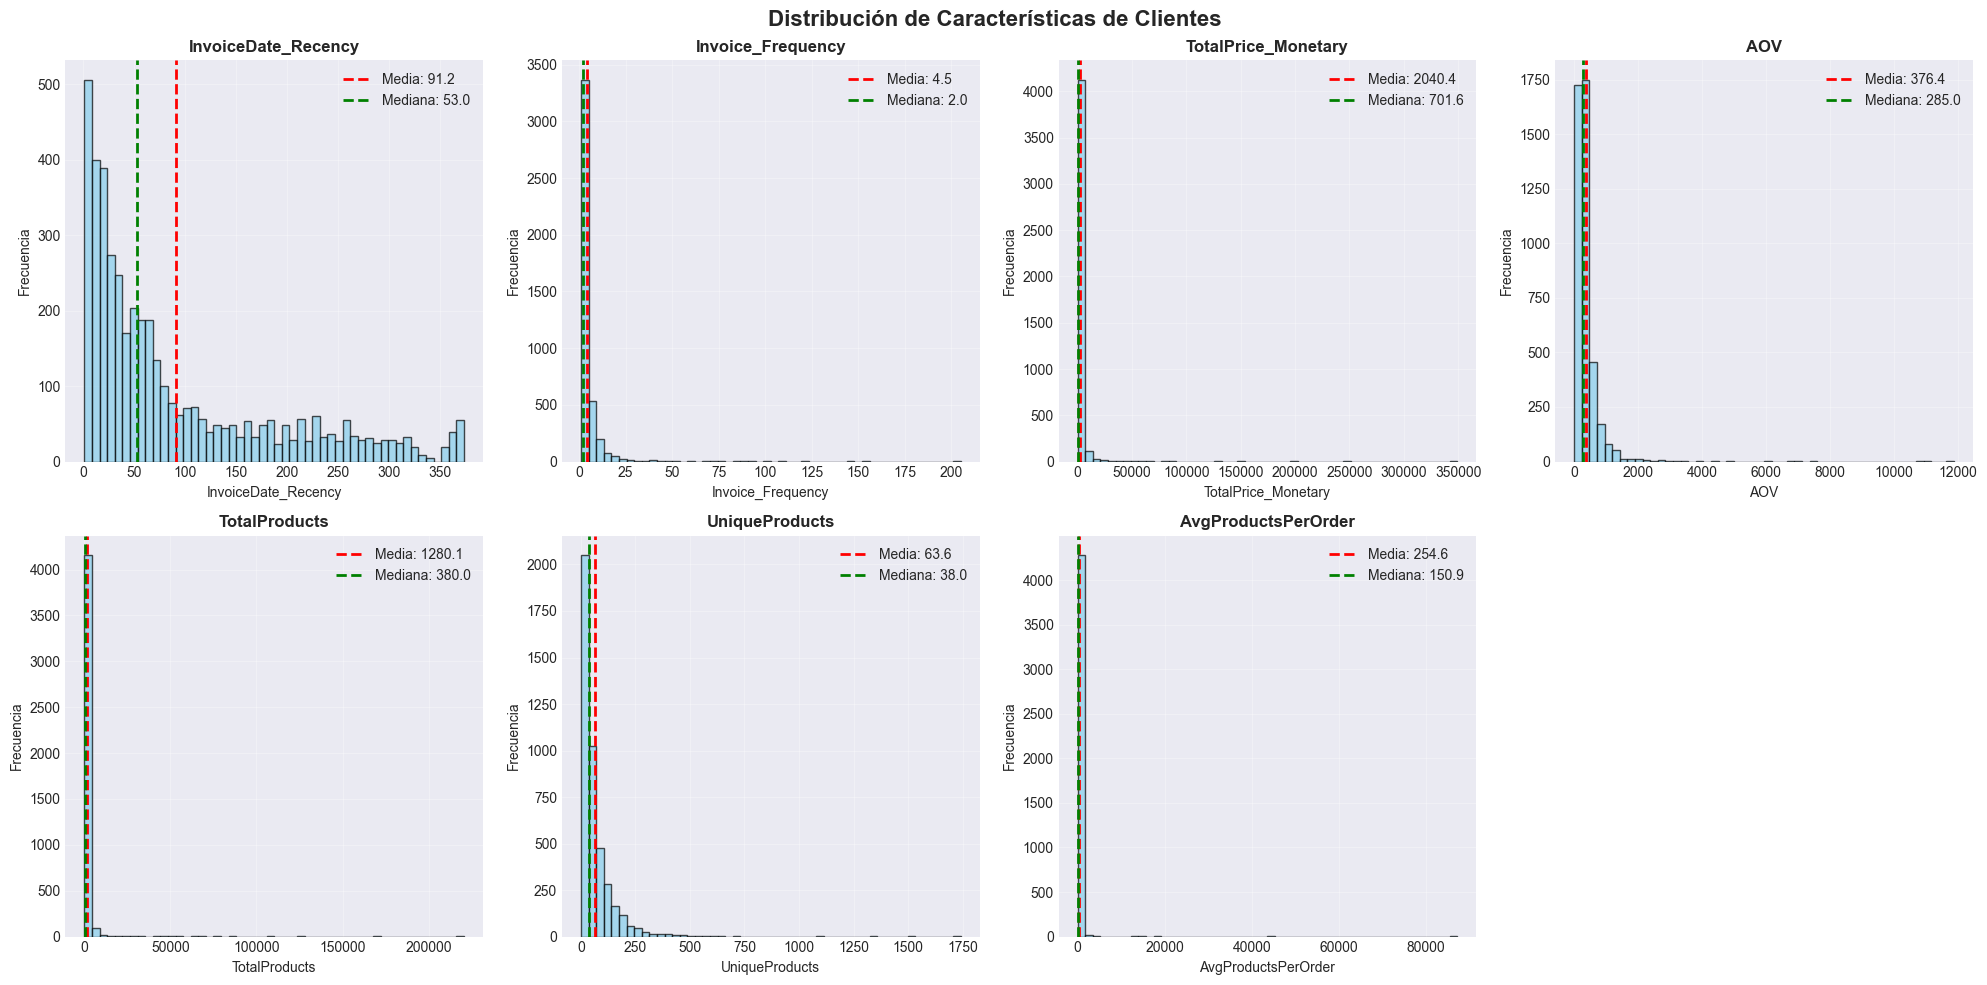

✓ Visualización de distribuciones completada


In [7]:
# Distribuciones de las características RFM
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Distribución de Características de Clientes', fontsize=16, fontweight='bold')

features = ['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV', 
            'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder']

for idx, feature in enumerate(features):
    row = idx // 4
    col = idx % 4
    
    # Histograma
    axes[row, col].hist(rfm[feature], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    axes[row, col].set_title(f'{feature}', fontweight='bold')
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel('Frecuencia')
    axes[row, col].grid(True, alpha=0.3)
    
    # Añadir estadísticas
    mean_val = rfm[feature].mean()
    median_val = rfm[feature].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Media: {mean_val:.1f}')
    axes[row, col].axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Mediana: {median_val:.1f}')
    axes[row, col].legend()

# Eliminar eje vacío
fig.delaxes(axes[1, 3])

plt.tight_layout()
plt.show()

print("✓ Visualización de distribuciones completada")

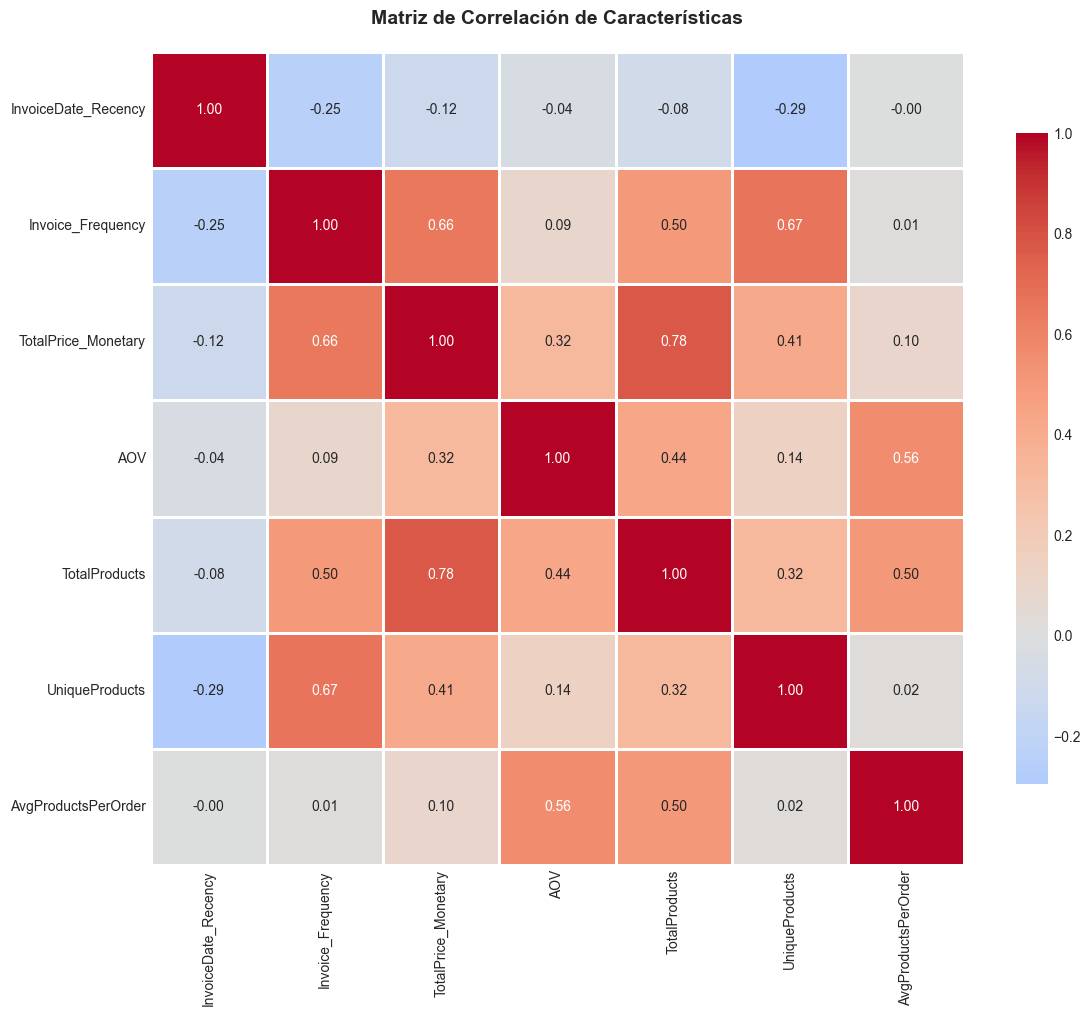


INTERPRETACIÓN DE CORRELACIONES

Correlaciones más fuertes:
  • TotalPrice_Monetary ↔ TotalProducts: 0.776
  • Invoice_Frequency ↔ UniqueProducts: 0.669
  • Invoice_Frequency ↔ TotalPrice_Monetary: 0.656
  • AOV ↔ AvgProductsPerOrder: 0.560
  • TotalProducts ↔ AvgProductsPerOrder: 0.502


In [8]:
# Matriz de correlación
fig, ax = plt.subplots(figsize=(12, 10))
features_for_corr = ['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV', 
                     'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder']
correlation_matrix = rfm[features_for_corr].corr()

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Matriz de Correlación de Características', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("INTERPRETACIÓN DE CORRELACIONES")
print("="*80)
print("\nCorrelaciones más fuertes:")
# Obtener correlaciones más fuertes (excluyendo diagonal)
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_pairs.append((
            correlation_matrix.columns[i],
            correlation_matrix.columns[j],
            correlation_matrix.iloc[i, j]
        ))

corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for feat1, feat2, corr in corr_pairs[:5]:
    print(f"  • {feat1} ↔ {feat2}: {corr:.3f}")

**Paso 7: Detección y Tratamiento de Outliers**

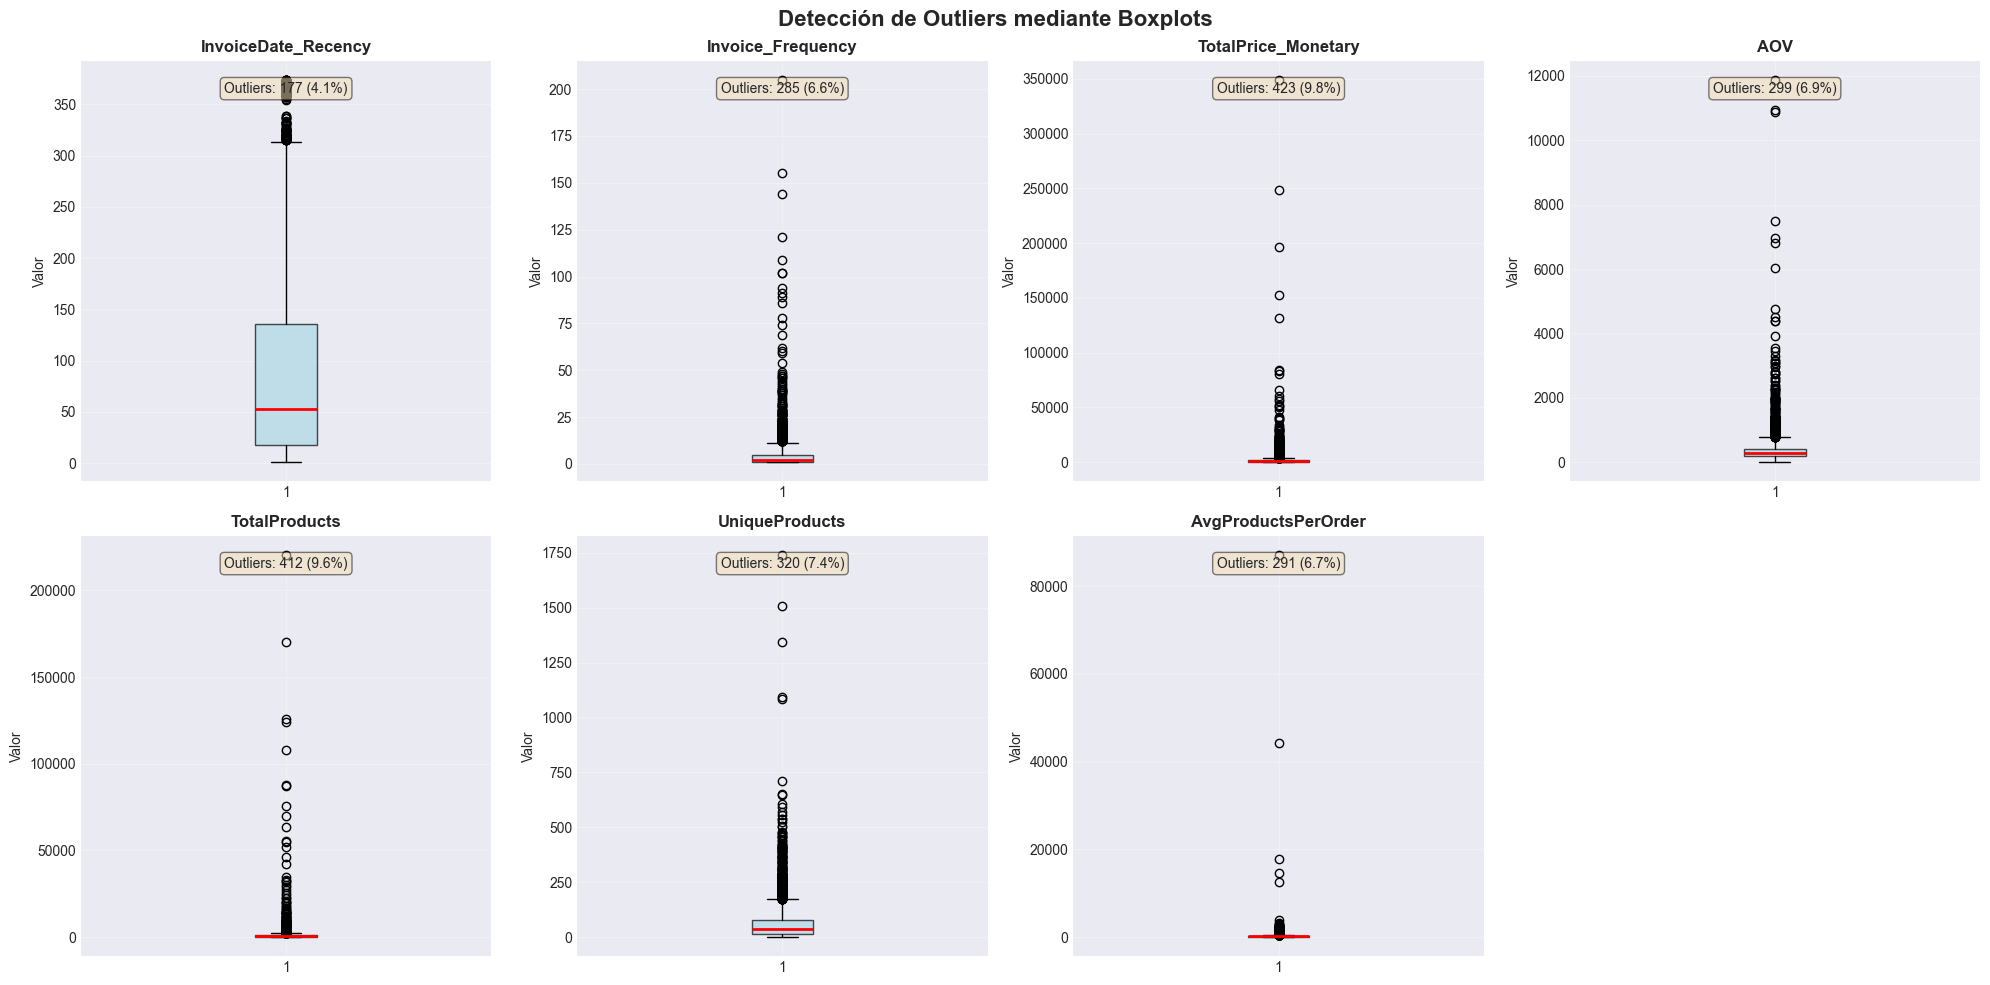

ESTRATEGIA DE TRATAMIENTO DE OUTLIERS

Para el clustering, mantendremos los outliers por las siguientes razones:
1. Representan clientes VIP o segmentos especiales de alto valor
2. Los algoritmos de clustering pueden identificarlos como grupos separados
3. Aplicar log-transformation y normalización reducirá su impacto
4. DBSCAN puede identificarlos como ruido si es necesario

Se aplicará transformación logarítmica a las variables sesgadas para reducir
el impacto de valores extremos mientras se preserva la información.



In [9]:
# Boxplots para detectar outliers
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Detección de Outliers mediante Boxplots', fontsize=16, fontweight='bold')

features = ['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV', 
            'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder']

for idx, feature in enumerate(features):
    row = idx // 4
    col = idx % 4
    
    axes[row, col].boxplot(rfm[feature], vert=True, patch_artist=True,
                           boxprops=dict(facecolor='lightblue', alpha=0.7),
                           medianprops=dict(color='red', linewidth=2))
    axes[row, col].set_title(f'{feature}', fontweight='bold')
    axes[row, col].set_ylabel('Valor')
    axes[row, col].grid(True, alpha=0.3)
    
    # Calcular outliers usando IQR
    Q1 = rfm[feature].quantile(0.25)
    Q3 = rfm[feature].quantile(0.75)
    IQR = Q3 - Q1
    outliers = rfm[(rfm[feature] < Q1 - 1.5*IQR) | (rfm[feature] > Q3 + 1.5*IQR)]
    axes[row, col].text(0.5, 0.95, f'Outliers: {len(outliers)} ({len(outliers)/len(rfm)*100:.1f}%)',
                       transform=axes[row, col].transAxes, ha='center', va='top',
                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

fig.delaxes(axes[1, 3])
plt.tight_layout()
plt.show()

print("="*80)
print("ESTRATEGIA DE TRATAMIENTO DE OUTLIERS")
print("="*80)
print("""
Para el clustering, mantendremos los outliers por las siguientes razones:
1. Representan clientes VIP o segmentos especiales de alto valor
2. Los algoritmos de clustering pueden identificarlos como grupos separados
3. Aplicar log-transformation y normalización reducirá su impacto
4. DBSCAN puede identificarlos como ruido si es necesario

Se aplicará transformación logarítmica a las variables sesgadas para reducir
el impacto de valores extremos mientras se preserva la información.
""")

**Paso 8: Transformación y Normalización de Datos**

TRANSFORMACIÓN LOGARÍTMICA

Aplicando transformación log(1+x) a variables sesgadas...
✓ Transformación logarítmica completada

NORMALIZACIÓN CON STANDARDSCALER
✓ Datos normalizados (media=0, std=1)

Forma del dataset normalizado: (4312, 7)

Estadísticas después de normalización:


,InvoiceDate_Recency,Invoice_Frequency,TotalPrice_Monetary,AOV,TotalProducts,UniqueProducts,AvgProductsPerOrder
count,4.312000e+03,4.312000e+03,4.312000e+03,4.312000e+03,4.312000e+03,4.312000e+03,4.312000e+03
mean,-9.063045e-17,6.385327e-17,2.306957e-16,4.020696e-16,-3.295653e-16,3.674653e-16,-3.822957e-16
std,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00
min,-2.433450e+00,-9.819103e-01,-4.086817e+00,-5.732823e+00,-3.660910e+00,-2.529221e+00,-4.462553e+00
25%,-7.013791e-01,-9.819103e-01,-6.855851e-01,-5.868556e-01,-6.268442e-01,-6.085284e-01,-5.026697e-01
50%,1.022598e-01,-3.946928e-01,-4.226108e-02,3.315147e-02,-1.034168e-02,6.735143e-02,4.175622e-02
75%,8.185384e-01,6.091622e-01,6.547718e-01,5.582428e-01,6.557964e-01,6.981085e-01,5.849778e-01
max,1.593249e+00,5.730367e+00,4.804321e+00,5.050732e+00,4.413266e+00,3.388426e+00,6.649867e+00


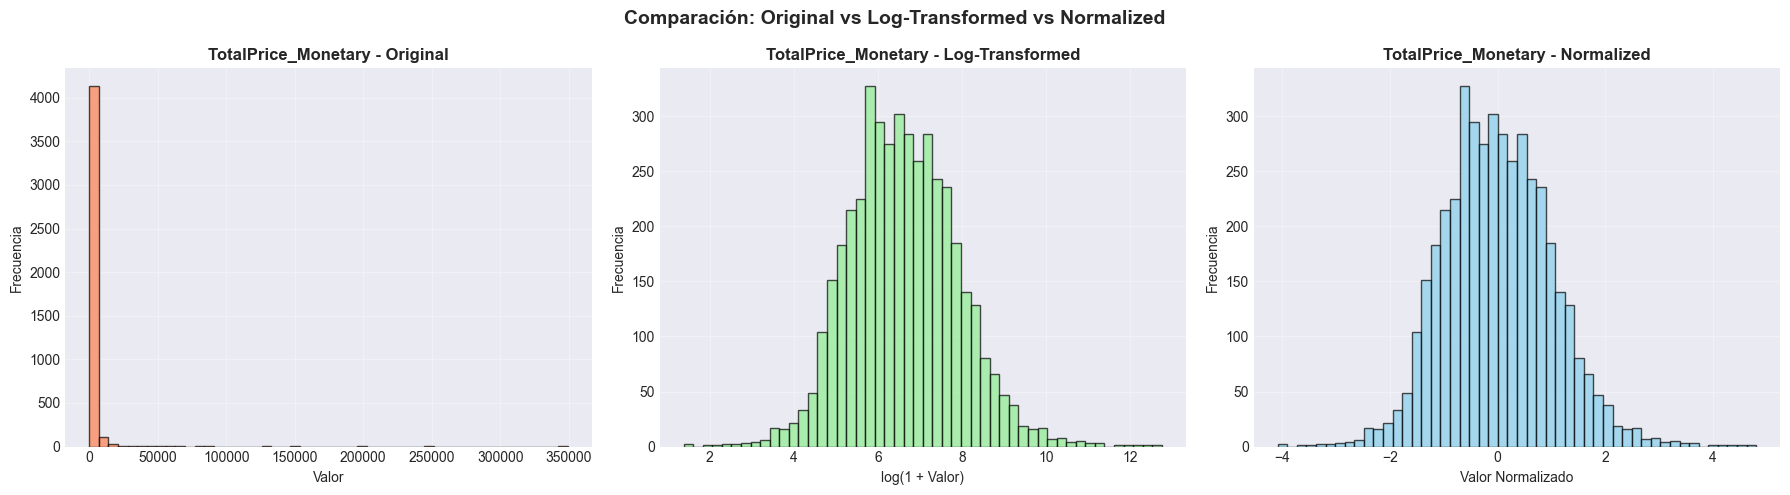

In [10]:
# Preparar datos para clustering
features_for_corr = ['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV', 
                     'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder']
rfm_features = rfm[features_for_corr].copy()

print("="*80)
print("TRANSFORMACIÓN LOGARÍTMICA")
print("="*80)
print("\nAplicando transformación log(1+x) a variables sesgadas...")

# Aplicar transformación logarítmica para reducir sesgo
rfm_log = rfm_features.copy()
for col in rfm_log.columns:
    rfm_log[col] = np.log1p(rfm_log[col])  # log(1 + x) para manejar valores cercanos a 0

print("✓ Transformación logarítmica completada")

# Normalización con StandardScaler
print("\n" + "="*80)
print("NORMALIZACIÓN CON STANDARDSCALER")
print("="*80)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=rfm_log.columns, index=rfm_log.index)

print("✓ Datos normalizados (media=0, std=1)")
print(f"\nForma del dataset normalizado: {rfm_scaled_df.shape}")
print("\nEstadísticas después de normalización:")
display(rfm_scaled_df.describe())

# Visualizar comparación antes y después
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Comparación: Original vs Log-Transformed vs Normalized', fontsize=14, fontweight='bold')

# Ejemplo con TotalPrice_Monetary
feature_example = 'TotalPrice_Monetary'

# Original
axes[0].hist(rfm_features[feature_example], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0].set_title(f'{feature_example} - Original', fontweight='bold')
axes[0].set_xlabel('Valor')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(True, alpha=0.3)

# Log-transformed
axes[1].hist(rfm_log[feature_example], bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[1].set_title(f'{feature_example} - Log-Transformed', fontweight='bold')
axes[1].set_xlabel('log(1 + Valor)')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, alpha=0.3)

# Normalized
axes[2].hist(rfm_scaled_df[feature_example], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[2].set_title(f'{feature_example} - Normalized', fontweight='bold')
axes[2].set_xlabel('Valor Normalizado')
axes[2].set_ylabel('Frecuencia')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Paso 9: Análisis de Componentes Principales (PCA)**

ANÁLISIS DE COMPONENTES PRINCIPALES (PCA)

✓ PCA completado con 7 componentes

Varianza explicada por cada componente:
  PC1: 62.75% (Acumulada: 62.75%)
  PC2: 19.43% (Acumulada: 82.18%)
  PC3: 7.99% (Acumulada: 90.18%)
  PC4: 5.57% (Acumulada: 95.75%)
  PC5: 4.19% (Acumulada: 99.94%)
  PC6: 0.06% (Acumulada: 100.00%)
  PC7: 0.00% (Acumulada: 100.00%)


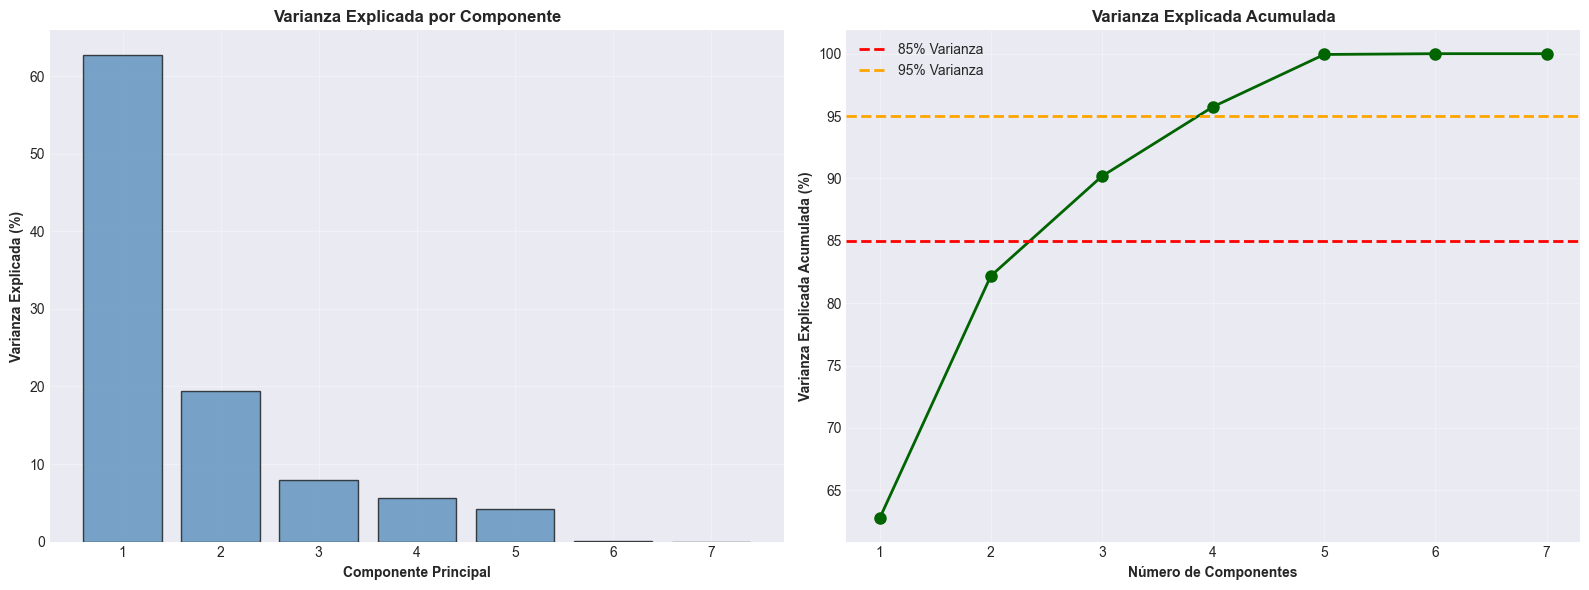


NÚMERO ÓPTIMO DE COMPONENTES
Para explicar el 85% de la varianza: 3 componentes
Para explicar el 95% de la varianza: 4 componentes

→ Seleccionaremos 3 componentes para el clustering


In [11]:
print("="*80)
print("ANÁLISIS DE COMPONENTES PRINCIPALES (PCA)")
print("="*80)

# Aplicar PCA con todos los componentes para analizar varianza
pca_full = PCA()
pca_full.fit(rfm_scaled)

# Varianza explicada
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"\n✓ PCA completado con {len(explained_variance)} componentes")
print("\nVarianza explicada por cada componente:")
for i, (var, cum_var) in enumerate(zip(explained_variance, cumulative_variance), 1):
    print(f"  PC{i}: {var*100:.2f}% (Acumulada: {cum_var*100:.2f}%)")

# Visualización de varianza explicada
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico de barras - varianza individual
axes[0].bar(range(1, len(explained_variance)+1), explained_variance*100, 
           color='steelblue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Componente Principal', fontweight='bold')
axes[0].set_ylabel('Varianza Explicada (%)', fontweight='bold')
axes[0].set_title('Varianza Explicada por Componente', fontweight='bold', fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(range(1, len(explained_variance)+1))

# Gráfico de línea - varianza acumulada
axes[1].plot(range(1, len(cumulative_variance)+1), cumulative_variance*100, 
            marker='o', linewidth=2, markersize=8, color='darkgreen')
axes[1].axhline(y=85, color='red', linestyle='--', linewidth=2, label='85% Varianza')
axes[1].axhline(y=95, color='orange', linestyle='--', linewidth=2, label='95% Varianza')
axes[1].set_xlabel('Número de Componentes', fontweight='bold')
axes[1].set_ylabel('Varianza Explicada Acumulada (%)', fontweight='bold')
axes[1].set_title('Varianza Explicada Acumulada', fontweight='bold', fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend()
axes[1].set_xticks(range(1, len(cumulative_variance)+1))

plt.tight_layout()
plt.show()

# Determinar número óptimo de componentes (≥ 85% varianza)
n_components_85 = np.argmax(cumulative_variance >= 0.85) + 1
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"\n{'='*80}")
print(f"NÚMERO ÓPTIMO DE COMPONENTES")
print(f"{'='*80}")
print(f"Para explicar el 85% de la varianza: {n_components_85} componentes")
print(f"Para explicar el 95% de la varianza: {n_components_95} componentes")
print(f"\n→ Seleccionaremos {n_components_85} componentes para el clustering")


✓ Dataset reducido a 3 dimensiones
Forma del dataset PCA: (4312, 3)

CONTRIBUCIÓN DE CARACTERÍSTICAS A LOS COMPONENTES PRINCIPALES

Loadings (pesos) de cada característica en los componentes:


,PC1,PC2,PC3
InvoiceDate_Recency,-0.254,0.493,0.831
Invoice_Frequency,0.361,-0.472,0.370
TotalPrice_Monetary,0.457,-0.045,0.159
AOV,0.346,0.496,-0.174
TotalProducts,0.460,0.048,0.089
UniqueProducts,0.382,-0.145,0.254
AvgProductsPerOrder,0.346,0.512,-0.212


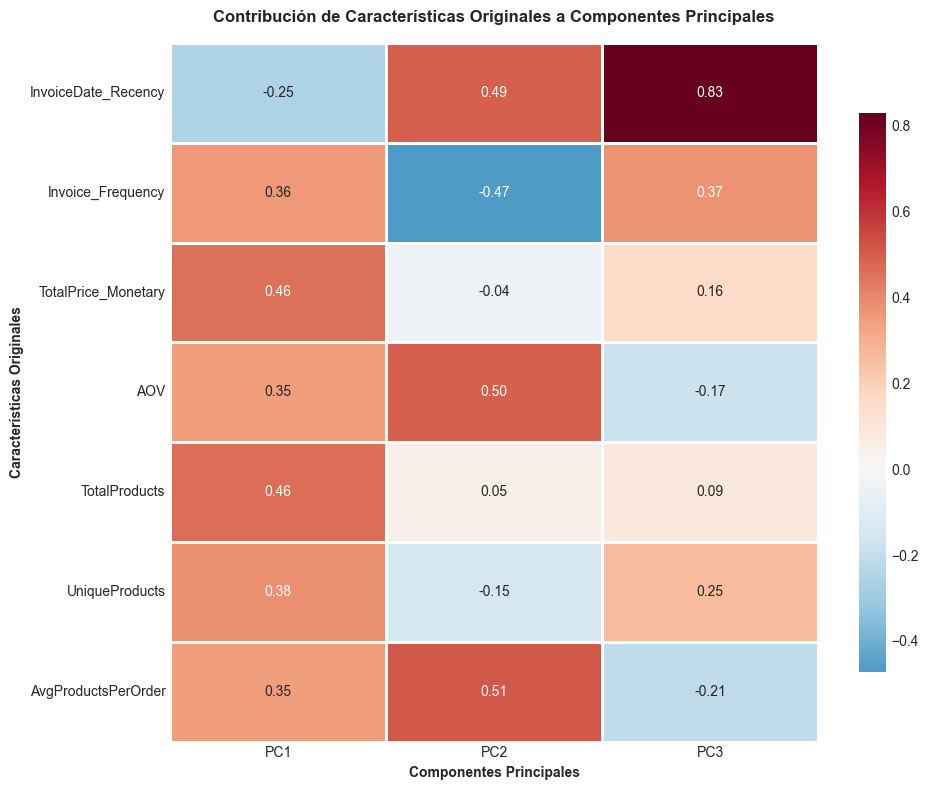


INTERPRETACIÓN DE COMPONENTES PRINCIPALES

PC1:
  Varianza explicada: 62.75%
  Características más importantes:
    + TotalProducts: 0.460
    + TotalPrice_Monetary: 0.457
    + UniqueProducts: 0.382

PC2:
  Varianza explicada: 19.43%
  Características más importantes:
    + AvgProductsPerOrder: 0.512
    + AOV: 0.496
    + InvoiceDate_Recency: 0.493

PC3:
  Varianza explicada: 7.99%
  Características más importantes:
    + InvoiceDate_Recency: 0.831
    + Invoice_Frequency: 0.370
    + UniqueProducts: 0.254


In [12]:
# Aplicar PCA con el número óptimo de componentes
pca = PCA(n_components=n_components_85, random_state=42)
rfm_pca = pca.fit_transform(rfm_scaled)

# Crear DataFrame con componentes principales
pca_columns = [f'PC{i+1}' for i in range(n_components_85)]
rfm_pca_df = pd.DataFrame(rfm_pca, columns=pca_columns, index=rfm.index)

print(f"\n✓ Dataset reducido a {n_components_85} dimensiones")
print(f"Forma del dataset PCA: {rfm_pca_df.shape}")

# Analizar contribución de características originales a cada componente
print("\n" + "="*80)
print("CONTRIBUCIÓN DE CARACTERÍSTICAS A LOS COMPONENTES PRINCIPALES")
print("="*80)

components_df = pd.DataFrame(
    pca.components_.T,
    columns=pca_columns,
    index=rfm_log.columns
)

print("\nLoadings (pesos) de cada característica en los componentes:")
display(components_df.round(3))

# Heatmap de contribuciones
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(components_df, annot=True, fmt='.2f', cmap='RdBu_r', 
            center=0, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Contribución de Características Originales a Componentes Principales', 
            fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Componentes Principales', fontweight='bold')
ax.set_ylabel('Características Originales', fontweight='bold')
plt.tight_layout()
plt.show()

# Interpretación de componentes
print("\n" + "="*80)
print("INTERPRETACIÓN DE COMPONENTES PRINCIPALES")
print("="*80)

for i, pc in enumerate(pca_columns):
    print(f"\n{pc}:")
    loadings = components_df[pc].abs().sort_values(ascending=False)
    print(f"  Varianza explicada: {pca.explained_variance_ratio_[i]*100:.2f}%")
    print(f"  Características más importantes:")
    for feat, val in loadings.head(3).items():
        original_val = components_df.loc[feat, pc]
        direction = "+" if original_val > 0 else "-"
        print(f"    {direction} {feat}: {abs(original_val):.3f}")

**Paso 10: Determinación del Número Óptimo de Clusters**

MÉTODO DEL CODO (ELBOW METHOD)

Calculando métricas para diferentes valores de K...
  K=2: Inertia=15479.06, Silhouette=0.367, Davies-Bouldin=1.017
  K=3: Inertia=11924.69, Silhouette=0.291, Davies-Bouldin=1.113
  K=4: Inertia=10053.74, Silhouette=0.269, Davies-Bouldin=1.153
  K=5: Inertia=8527.54, Silhouette=0.273, Davies-Bouldin=1.071
  K=6: Inertia=7605.54, Silhouette=0.260, Davies-Bouldin=1.081
  K=7: Inertia=6864.71, Silhouette=0.255, Davies-Bouldin=1.098
  K=8: Inertia=6294.79, Silhouette=0.253, Davies-Bouldin=1.110
  K=9: Inertia=5867.58, Silhouette=0.258, Davies-Bouldin=1.122
  K=10: Inertia=5454.67, Silhouette=0.250, Davies-Bouldin=1.058


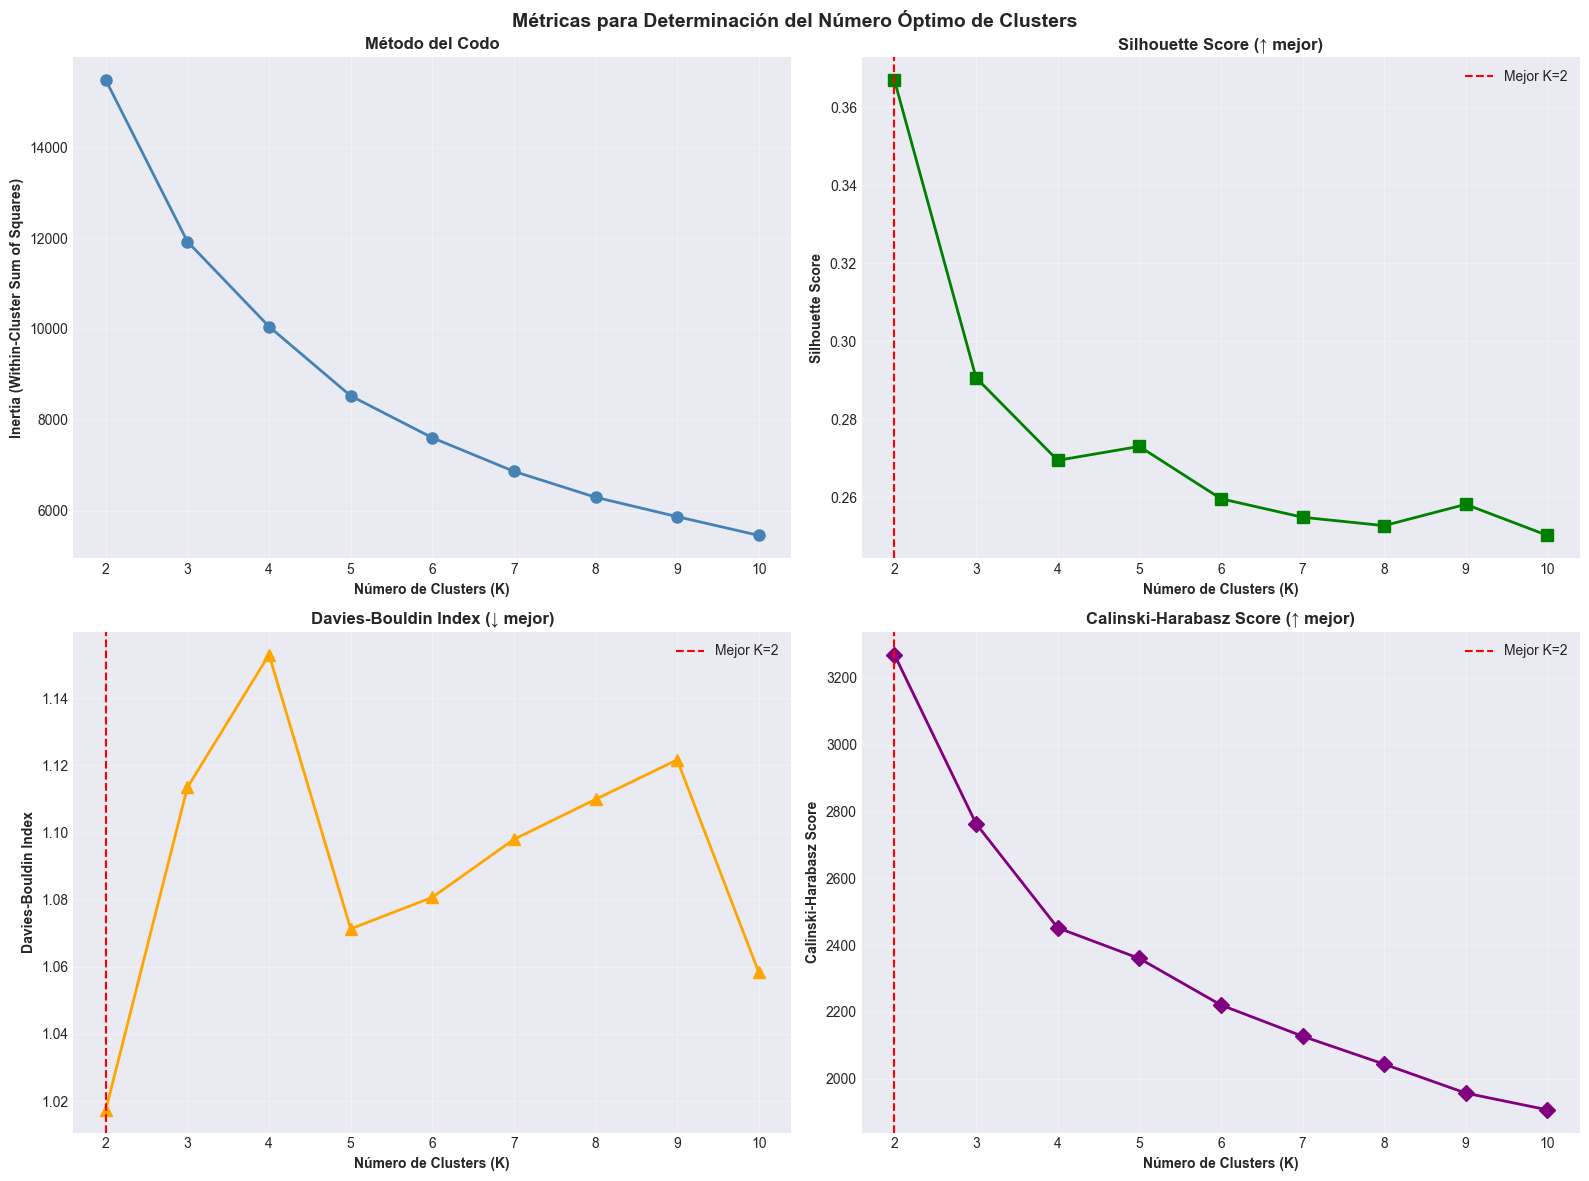


RECOMENDACIONES DE NÚMERO ÓPTIMO DE CLUSTERS
Silhouette Score sugiere: K = 2
Davies-Bouldin Index sugiere: K = 2
Calinski-Harabasz Score sugiere: K = 2

→ Seleccionaremos K = 2 basándonos en Silhouette Score


In [13]:
print("="*80)
print("MÉTODO DEL CODO (ELBOW METHOD)")
print("="*80)

# Rango de clusters a probar
K_range = range(2, 11)
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

print("\nCalculando métricas para diferentes valores de K...")

for k in K_range:
    # Aplicar K-Means
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, 
                   max_iter=300, random_state=42)
    labels = kmeans.fit_predict(rfm_pca)
    
    # Calcular métricas
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_pca, labels))
    davies_bouldin_scores.append(davies_bouldin_score(rfm_pca, labels))
    calinski_harabasz_scores.append(calinski_harabasz_score(rfm_pca, labels))
    
    print(f"  K={k}: Inertia={kmeans.inertia_:.2f}, "
          f"Silhouette={silhouette_scores[-1]:.3f}, "
          f"Davies-Bouldin={davies_bouldin_scores[-1]:.3f}")

# Visualización de métricas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Métricas para Determinación del Número Óptimo de Clusters', 
            fontsize=14, fontweight='bold')

# 1. Método del Codo (Inertia)
axes[0, 0].plot(K_range, inertias, marker='o', linewidth=2, markersize=8, color='steelblue')
axes[0, 0].set_xlabel('Número de Clusters (K)', fontweight='bold')
axes[0, 0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontweight='bold')
axes[0, 0].set_title('Método del Codo', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(K_range)

# 2. Silhouette Score (mayor es mejor)
axes[0, 1].plot(K_range, silhouette_scores, marker='s', linewidth=2, markersize=8, color='green')
axes[0, 1].set_xlabel('Número de Clusters (K)', fontweight='bold')
axes[0, 1].set_ylabel('Silhouette Score', fontweight='bold')
axes[0, 1].set_title('Silhouette Score (↑ mejor)', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xticks(K_range)
best_k_silhouette = K_range[np.argmax(silhouette_scores)]
axes[0, 1].axvline(best_k_silhouette, color='red', linestyle='--', 
                   label=f'Mejor K={best_k_silhouette}')
axes[0, 1].legend()

# 3. Davies-Bouldin Index (menor es mejor)
axes[1, 0].plot(K_range, davies_bouldin_scores, marker='^', linewidth=2, markersize=8, color='orange')
axes[1, 0].set_xlabel('Número de Clusters (K)', fontweight='bold')
axes[1, 0].set_ylabel('Davies-Bouldin Index', fontweight='bold')
axes[1, 0].set_title('Davies-Bouldin Index (↓ mejor)', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xticks(K_range)
best_k_davies = K_range[np.argmin(davies_bouldin_scores)]
axes[1, 0].axvline(best_k_davies, color='red', linestyle='--', 
                  label=f'Mejor K={best_k_davies}')
axes[1, 0].legend()

# 4. Calinski-Harabasz Index (mayor es mejor)
axes[1, 1].plot(K_range, calinski_harabasz_scores, marker='D', linewidth=2, markersize=8, color='purple')
axes[1, 1].set_xlabel('Número de Clusters (K)', fontweight='bold')
axes[1, 1].set_ylabel('Calinski-Harabasz Score', fontweight='bold')
axes[1, 1].set_title('Calinski-Harabasz Score (↑ mejor)', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_xticks(K_range)
best_k_calinski = K_range[np.argmax(calinski_harabasz_scores)]
axes[1, 1].axvline(best_k_calinski, color='red', linestyle='--', 
                  label=f'Mejor K={best_k_calinski}')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Resumen de recomendaciones
print("\n" + "="*80)
print("RECOMENDACIONES DE NÚMERO ÓPTIMO DE CLUSTERS")
print("="*80)
print(f"Silhouette Score sugiere: K = {best_k_silhouette}")
print(f"Davies-Bouldin Index sugiere: K = {best_k_davies}")
print(f"Calinski-Harabasz Score sugiere: K = {best_k_calinski}")
print(f"\n→ Seleccionaremos K = {best_k_silhouette} basándonos en Silhouette Score")

# Guardar el K óptimo
optimal_k = best_k_silhouette

**Paso 11: Aplicación de K-Means Clustering**

K-MEANS CLUSTERING CON K=2

✓ Clustering completado con 2 clusters

Distribución de clientes por cluster:
  Cluster 0: 2,050 clientes (47.5%)
  Cluster 1: 2,262 clientes (52.5%)

MÉTRICAS DE CALIDAD DEL CLUSTERING
Silhouette Score: 0.3670
  → Rango: [-1, 1]. Valores cercanos a 1 indican clusters bien separados
Davies-Bouldin Index: 1.0174
  → Valores más bajos indican mejor clustering
Calinski-Harabasz Score: 3268.96
  → Valores más altos indican clusters densos y bien separados


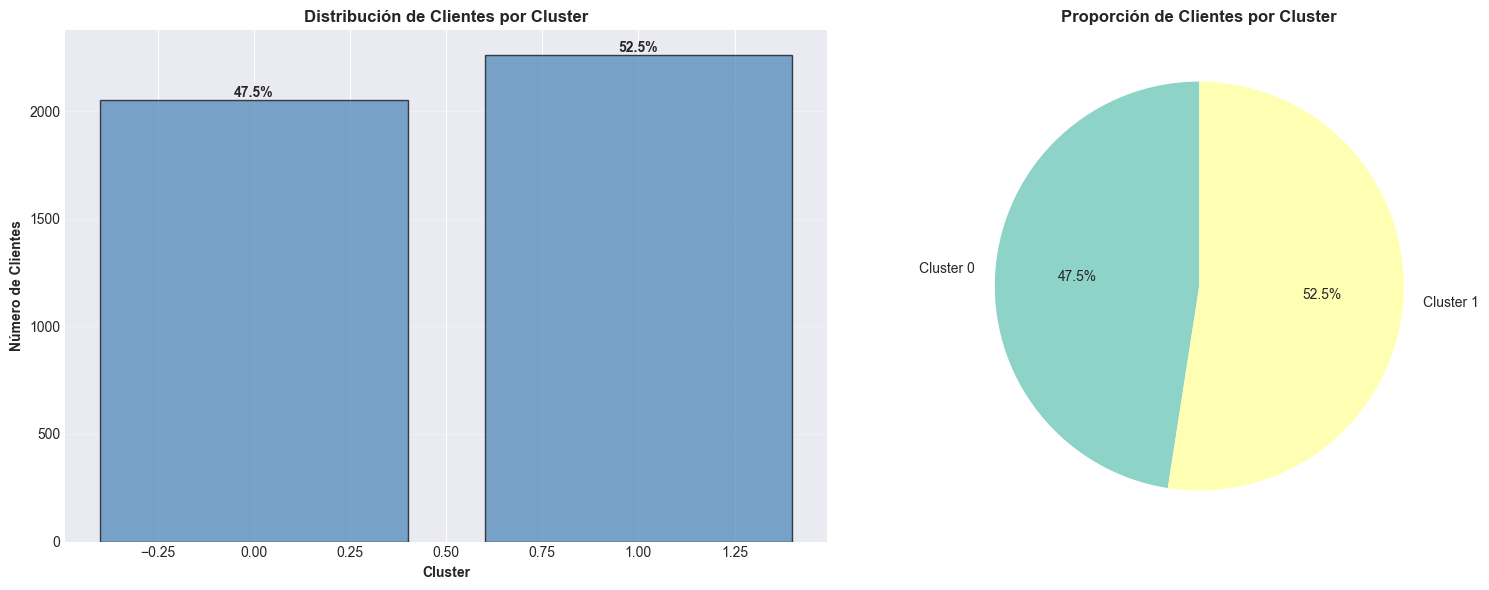

In [14]:
print("="*80)
print(f"K-MEANS CLUSTERING CON K={optimal_k}")
print("="*80)

# Aplicar K-Means con el K óptimo
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10,
                     max_iter=300, random_state=42)
cluster_labels = kmeans_final.fit_predict(rfm_pca)

# Añadir etiquetas de cluster al dataset original
rfm['Cluster'] = cluster_labels
rfm_pca_df['Cluster'] = cluster_labels

print(f"\n✓ Clustering completado con {optimal_k} clusters")
print(f"\nDistribución de clientes por cluster:")
cluster_counts = rfm['Cluster'].value_counts().sort_index()
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(rfm)) * 100
    print(f"  Cluster {cluster_id}: {count:,} clientes ({percentage:.1f}%)")

# Métricas finales
final_silhouette = silhouette_score(rfm_pca, cluster_labels)
final_davies_bouldin = davies_bouldin_score(rfm_pca, cluster_labels)
final_calinski = calinski_harabasz_score(rfm_pca, cluster_labels)

print(f"\n{'='*80}")
print("MÉTRICAS DE CALIDAD DEL CLUSTERING")
print(f"{'='*80}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"  → Rango: [-1, 1]. Valores cercanos a 1 indican clusters bien separados")
print(f"Davies-Bouldin Index: {final_davies_bouldin:.4f}")
print(f"  → Valores más bajos indican mejor clustering")
print(f"Calinski-Harabasz Score: {final_calinski:.2f}")
print(f"  → Valores más altos indican clusters densos y bien separados")

# Visualización de distribución de clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico de barras
axes[0].bar(cluster_counts.index, cluster_counts.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Cluster', fontweight='bold')
axes[0].set_ylabel('Número de Clientes', fontweight='bold')
axes[0].set_title('Distribución de Clientes por Cluster', fontweight='bold', fontsize=12)
axes[0].grid(True, alpha=0.3, axis='y')

# Añadir etiquetas de porcentaje
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(rfm)) * 100
    axes[0].text(cluster_id, count, f'{percentage:.1f}%', 
                ha='center', va='bottom', fontweight='bold')

# Gráfico de pastel
colors = plt.cm.Set3(range(optimal_k))
axes[1].pie(cluster_counts.values, labels=[f'Cluster {i}' for i in cluster_counts.index],
           autopct='%1.1f%%', startangle=90, colors=colors)
axes[1].set_title('Proporción de Clientes por Cluster', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

**Paso 12: Visualización de Clusters en Espacio PCA**

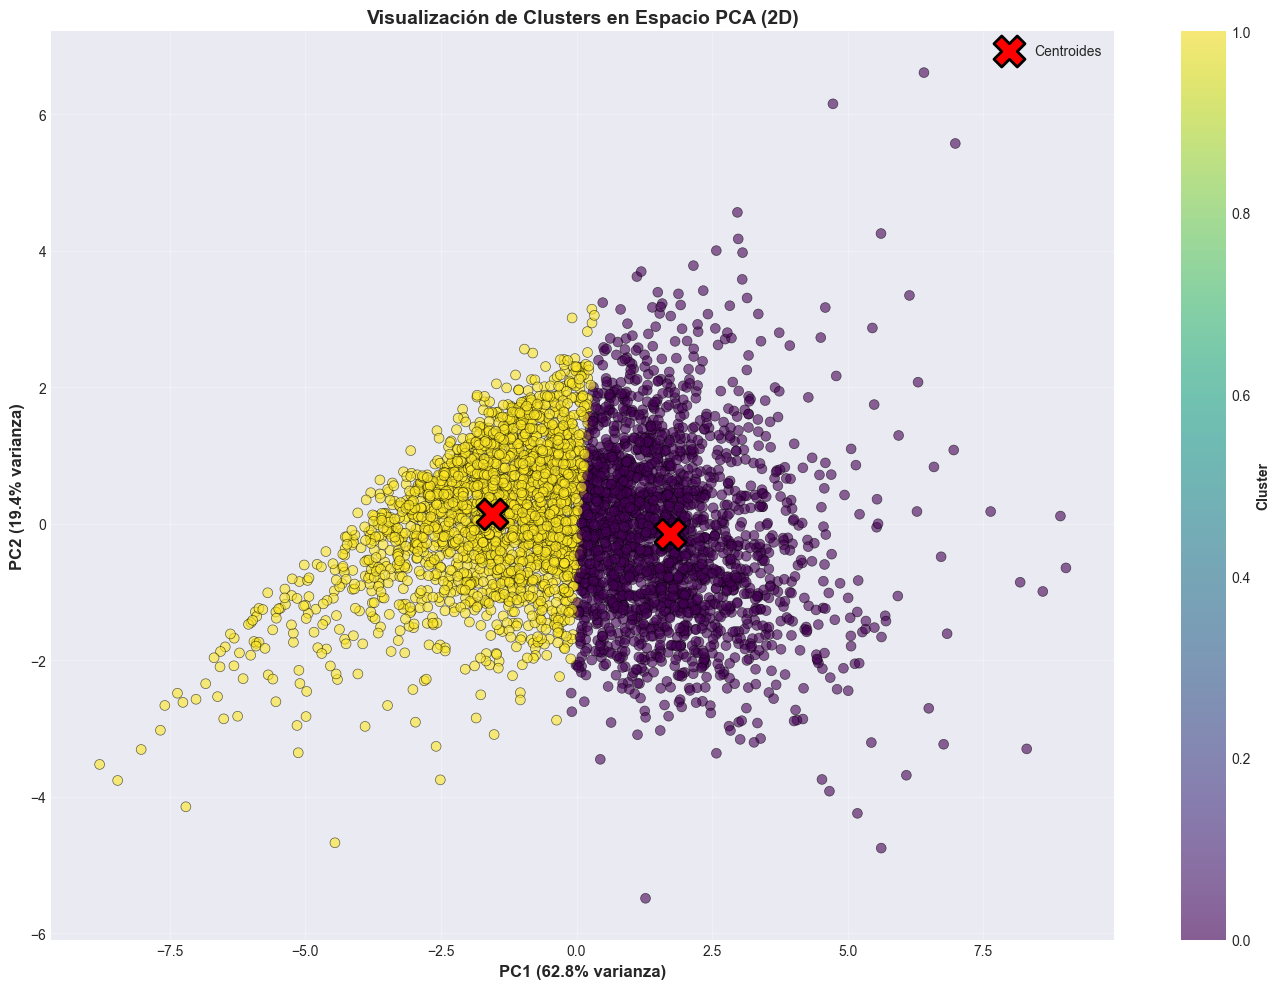

In [15]:
# Visualización 2D de clusters (primeros 2 componentes principales)
fig, ax = plt.subplots(figsize=(14, 10))

# Scatter plot de clientes coloreados por cluster
scatter = ax.scatter(rfm_pca_df['PC1'], rfm_pca_df['PC2'], 
                    c=rfm_pca_df['Cluster'], cmap='viridis',
                    s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

# Añadir centroides
centroides_pca = kmeans_final.cluster_centers_
ax.scatter(centroides_pca[:, 0], centroides_pca[:, 1], 
          c='red', marker='X', s=500, edgecolors='black', 
          linewidth=2, label='Centroides', zorder=5)

# Configuración del gráfico
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)', fontweight='bold', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)', fontweight='bold', fontsize=12)
ax.set_title('Visualización de Clusters en Espacio PCA (2D)', fontweight='bold', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Cluster', fontweight='bold')

plt.tight_layout()
plt.show()

# Visualización 3D interactiva con Plotly (si hay al menos 3 componentes)
if n_components_85 >= 3:
    fig_3d = px.scatter_3d(
        x=rfm_pca_df['PC1'], 
        y=rfm_pca_df['PC2'], 
        z=rfm_pca_df['PC3'],
        color=rfm_pca_df['Cluster'].astype(str),
        labels={'x': 'PC1', 'y': 'PC2', 'z': 'PC3', 'color': 'Cluster'},
        title='Visualización 3D de Clusters en Espacio PCA',
        color_discrete_sequence=px.colors.qualitative.Set3
    )
    fig_3d.update_traces(marker=dict(size=4, opacity=0.7))
    fig_3d.update_layout(width=900, height=700)
    fig_3d.show()
else:
    print("Solo hay 2 componentes principales, visualización 3D no disponible.")

**Paso 13: Análisis de Perfiles de Clusters (Caracterización)**

ANÁLISIS DE PERFILES DE CLUSTERS

✓ Perfiles de clusters calculados

Estadísticas promedio por cluster:


,InvoiceDate_Recency,Invoice_Frequency,TotalPrice_Monetary,AOV,TotalProducts,UniqueProducts,AvgProductsPerOrder
Cluster,,,,,,,
0,46.31,7.47,3872.63,523.68,2476.98,107.77,391.81
1,131.83,1.72,379.90,242.87,195.30,23.66,130.29


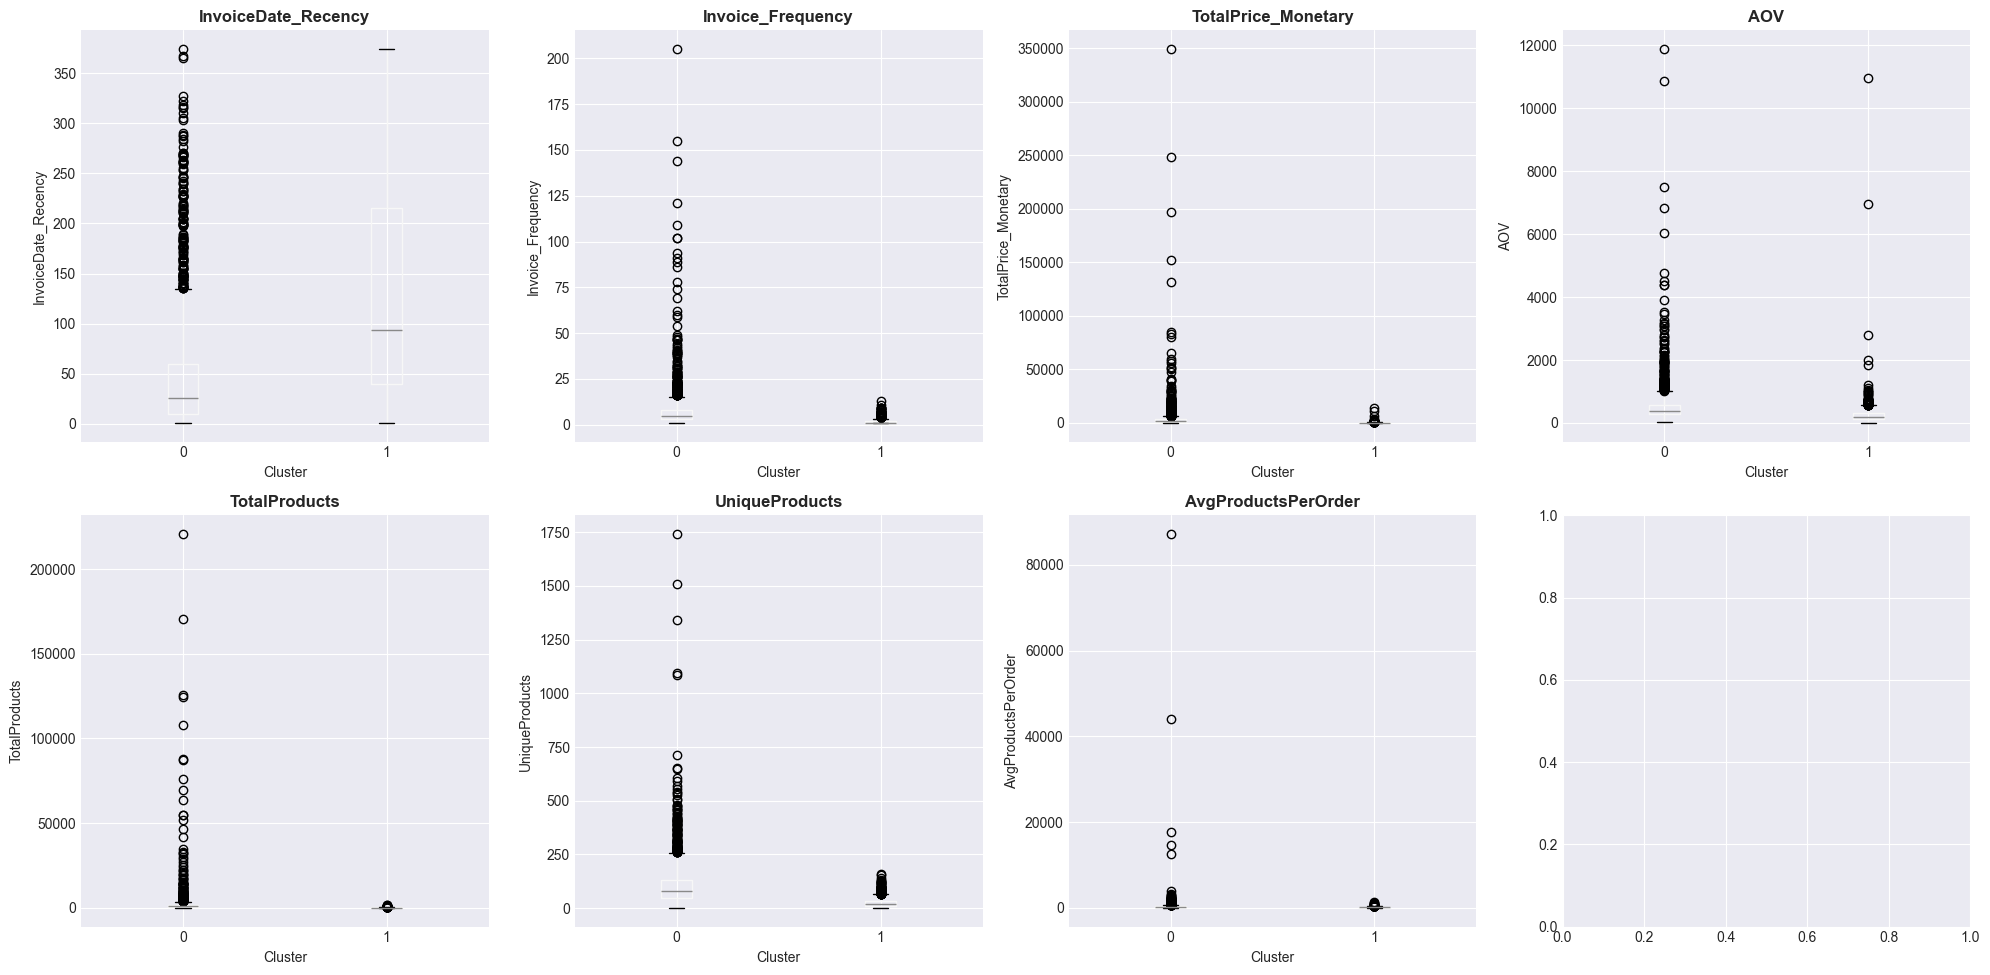

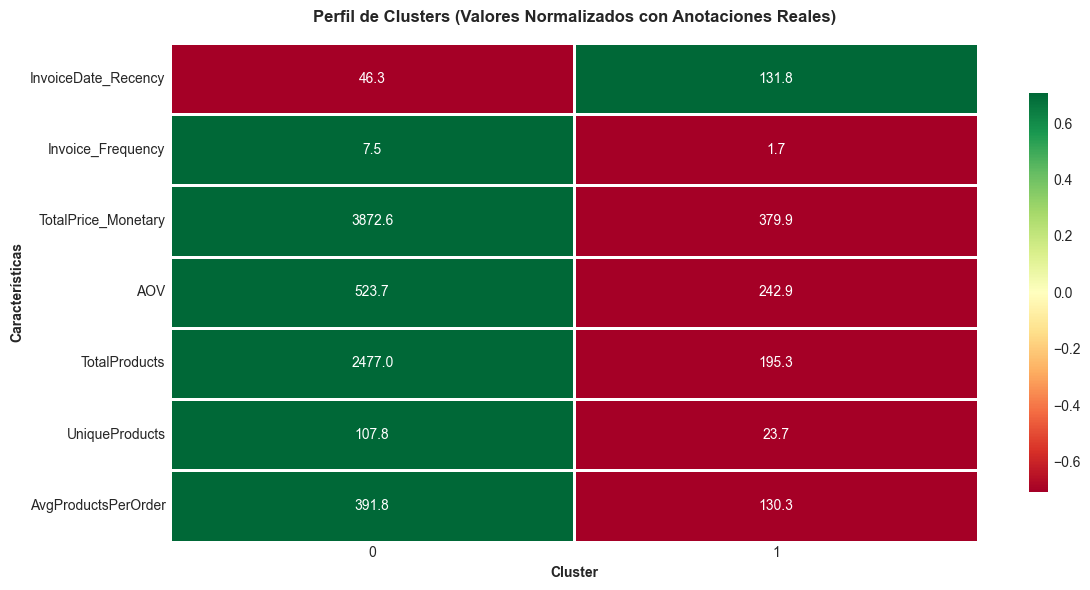

In [16]:
print("="*80)
print("ANÁLISIS DE PERFILES DE CLUSTERS")
print("="*80)

# Calcular estadísticas por cluster (usando valores originales, no normalizados)
cluster_profiles = rfm.groupby('Cluster')[features_for_corr].agg(['mean', 'median', 'std']).round(2)

print("\n✓ Perfiles de clusters calculados")
print("\nEstadísticas promedio por cluster:")
display(rfm.groupby('Cluster')[features_for_corr].mean().round(2))

# Visualización de perfiles mediante boxplots
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Distribución de Características por Cluster', fontsize=16, fontweight='bold')

for idx, feature in enumerate(features_for_corr):
    row = idx // 4
    col = idx % 4
    
    # Boxplot por cluster
    rfm.boxplot(column=feature, by='Cluster', ax=axes[row, col])
    axes[row, col].set_title(f'{feature}', fontweight='bold')
    axes[row, col].set_xlabel('Cluster')
    axes[row, col].set_ylabel(feature)
    axes[row, col].get_figure().suptitle('')  # Eliminar título automático
    
plt.tight_layout()
plt.show()

# Heatmap de promedios por cluster
cluster_means = rfm.groupby('Cluster')[features_for_corr].mean()

# Normalizar para visualización (por columna)
cluster_means_norm = (cluster_means - cluster_means.mean()) / cluster_means.std()

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(cluster_means_norm.T, annot=cluster_means.T.round(1), fmt='.1f', 
           cmap='RdYlGn', center=0, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Perfil de Clusters (Valores Normalizados con Anotaciones Reales)', 
            fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Cluster', fontweight='bold')
ax.set_ylabel('Características', fontweight='bold')
plt.tight_layout()
plt.show()

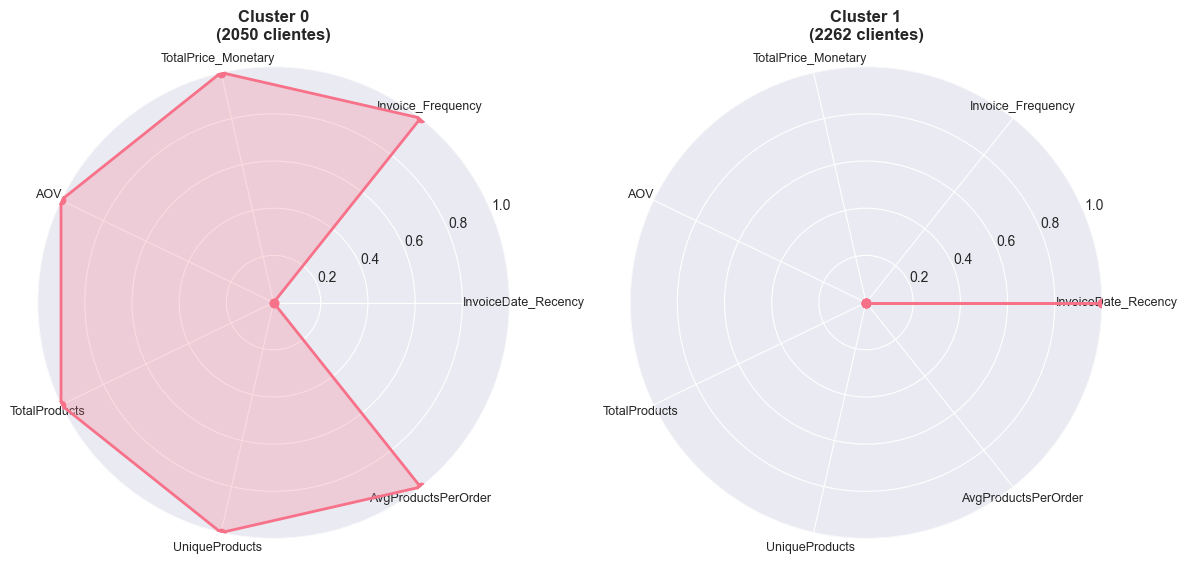


INTERPRETACIÓN DE CLUSTERS

CLUSTER 0 (2050 clientes - 47.5%)

Características principales:
  • InvoiceDate_Recency: 46.3 días (última compra)
  • Invoice_Frequency: 7.5 compras
  • TotalPrice_Monetary: £3872.63 (valor total)
  • AOV: £523.68 (valor promedio por orden)
  • Total Products: 2477 productos
  • Unique Products: 108 productos únicos
  • Avg Products/Order: 391.8 productos/orden

CLUSTER 1 (2262 clientes - 52.5%)

Características principales:
  • InvoiceDate_Recency: 131.8 días (última compra)
  • Invoice_Frequency: 1.7 compras
  • TotalPrice_Monetary: £379.90 (valor total)
  • AOV: £242.87 (valor promedio por orden)
  • Total Products: 195 productos
  • Unique Products: 24 productos únicos
  • Avg Products/Order: 130.3 productos/orden


In [17]:
# Gráfico de radar (spider chart) para comparar clusters
from math import pi

# Preparar datos para radar chart (usar promedios normalizados entre 0 y 1)
cluster_means_scaled = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

categories = list(cluster_means_scaled.columns)
N = len(categories)

# Ángulos para cada eje
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# Crear figura
fig, axes = plt.subplots(1, optimal_k, figsize=(6*optimal_k, 6), 
                        subplot_kw=dict(projection='polar'))

if optimal_k == 1:
    axes = [axes]

# Crear un radar chart para cada cluster
for idx, cluster_id in enumerate(sorted(rfm['Cluster'].unique())):
    ax = axes[idx]
    
    values = cluster_means_scaled.loc[cluster_id].tolist()
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, label=f'Cluster {cluster_id}')
    ax.fill(angles, values, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, size=9)
    ax.set_ylim(0, 1)
    ax.set_title(f'Cluster {cluster_id}\n({cluster_counts[cluster_id]} clientes)', 
                fontweight='bold', size=12, pad=20)
    ax.grid(True)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("INTERPRETACIÓN DE CLUSTERS")
print("="*80)

# Interpretar cada cluster
for cluster_id in sorted(rfm['Cluster'].unique()):
    cluster_data = rfm[rfm['Cluster'] == cluster_id][features_for_corr]
    
    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} ({cluster_counts[cluster_id]} clientes - {cluster_counts[cluster_id]/len(rfm)*100:.1f}%)")
    print(f"{'='*80}")
    
    print(f"\nCaracterísticas principales:")
    print(f"  • InvoiceDate_Recency: {cluster_data['InvoiceDate_Recency'].mean():.1f} días (última compra)")
    print(f"  • Invoice_Frequency: {cluster_data['Invoice_Frequency'].mean():.1f} compras")
    print(f"  • TotalPrice_Monetary: £{cluster_data['TotalPrice_Monetary'].mean():.2f} (valor total)")
    print(f"  • AOV: £{cluster_data['AOV'].mean():.2f} (valor promedio por orden)")
    print(f"  • Total Products: {cluster_data['TotalProducts'].mean():.0f} productos")
    print(f"  • Unique Products: {cluster_data['UniqueProducts'].mean():.0f} productos únicos")
    print(f"  • Avg Products/Order: {cluster_data['AvgProductsPerOrder'].mean():.1f} productos/orden")

**Paso 14: Comparación con Otros Algoritmos de Clustering**

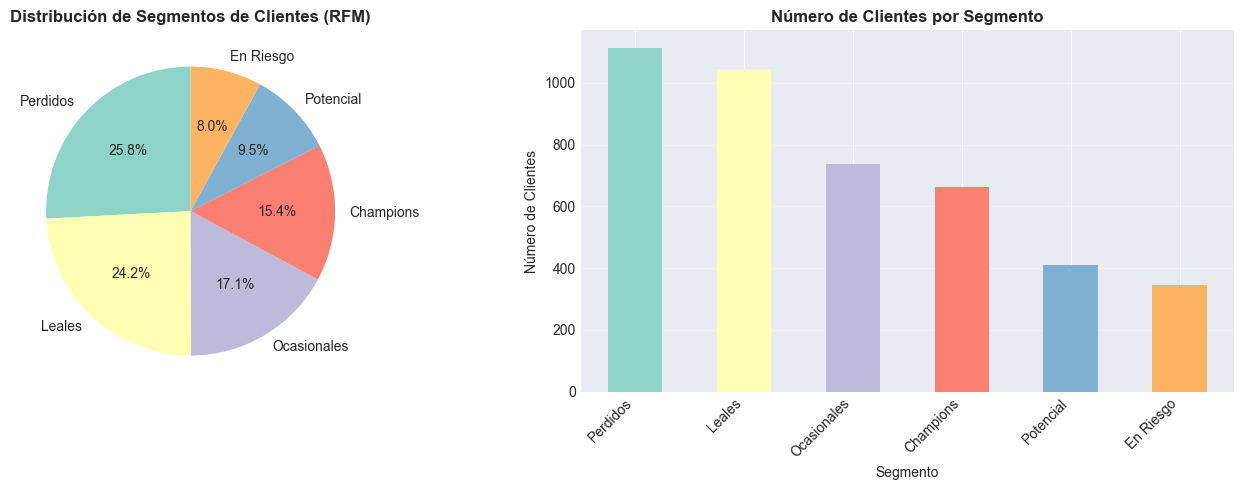


Distribución de Segmentos:
Segmento_RFM
Perdidos       1114
Leales         1044
Ocasionales     737
Champions       662
Potencial       411
En Riesgo       344
Name: count, dtype: int64

Características promedio por segmento:
              InvoiceDate_Recency  Invoice_Frequency  TotalPrice_Monetary
Segmento_RFM                                                             
Champions                   10.18              13.86              7643.04
En Riesgo                  158.12               4.69              1795.53
Leales                      38.24               5.05              1946.92
Ocasionales                 54.19               1.45               535.11
Perdidos                   220.79               1.28               435.24
Potencial                   15.02               1.59               508.66


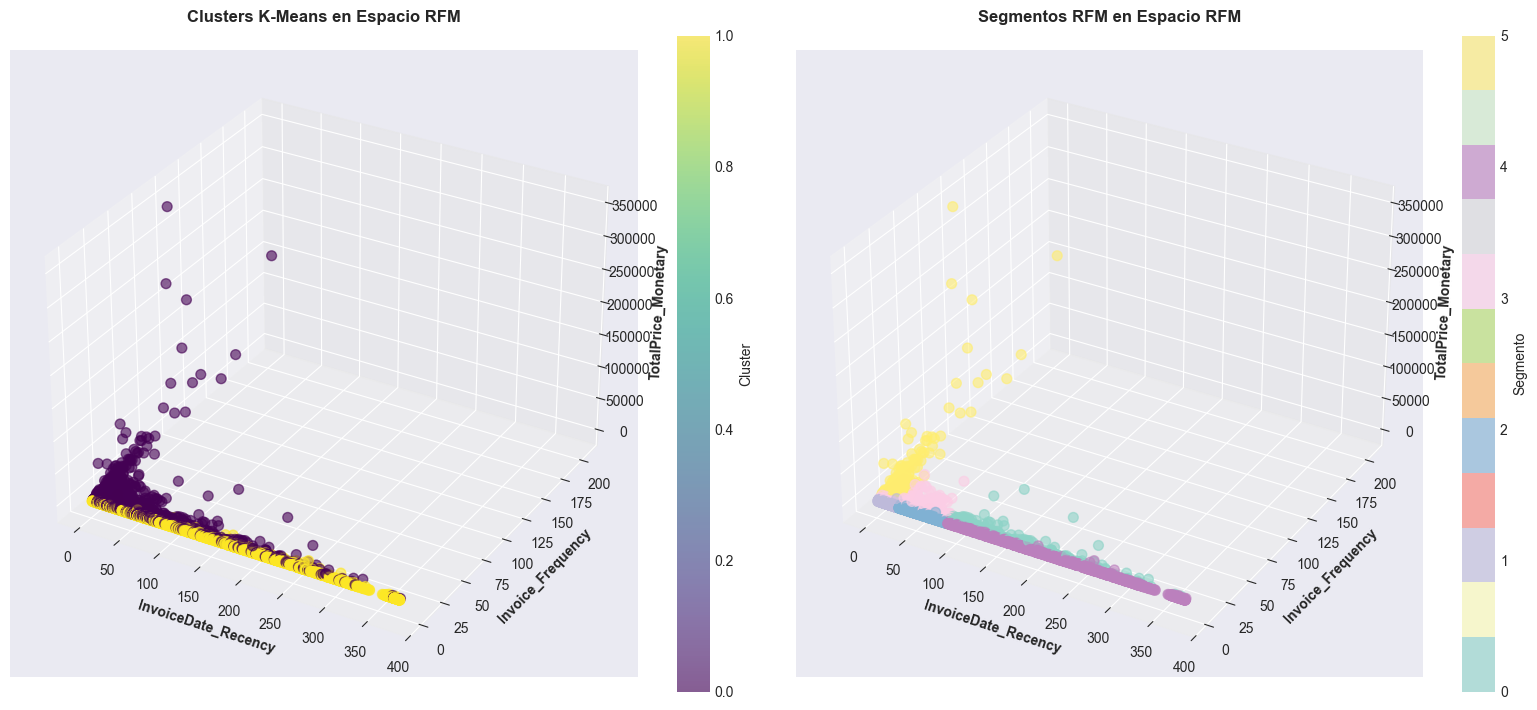

In [18]:
# Segmentación de clientes basada en características
# Definir umbrales basados en percentiles para clasificación
recency_q33 = rfm['InvoiceDate_Recency'].quantile(0.33)
recency_q66 = rfm['InvoiceDate_Recency'].quantile(0.66)
frequency_q33 = rfm['Invoice_Frequency'].quantile(0.33)
frequency_q66 = rfm['Invoice_Frequency'].quantile(0.66)
monetary_q33 = rfm['TotalPrice_Monetary'].quantile(0.33)
monetary_q66 = rfm['TotalPrice_Monetary'].quantile(0.66)

def segment_customer(row):
    """Clasifica clientes en segmentos basados en RFM"""
    r_score = 3 if row['InvoiceDate_Recency'] <= recency_q33 else (2 if row['InvoiceDate_Recency'] <= recency_q66 else 1)
    f_score = 1 if row['Invoice_Frequency'] <= frequency_q33 else (2 if row['Invoice_Frequency'] <= frequency_q66 else 3)
    m_score = 1 if row['TotalPrice_Monetary'] <= monetary_q33 else (2 if row['TotalPrice_Monetary'] <= monetary_q66 else 3)
    
    # Clientes Champions (alta recencia, frecuencia y valor)
    if r_score == 3 and f_score == 3 and m_score == 3:
        return 'Champions'
    # Clientes Leales (alta frecuencia y valor, recencia media/alta)
    elif f_score >= 2 and m_score >= 2 and r_score >= 2:
        return 'Leales'
    # Clientes Potenciales (alta recencia pero baja frecuencia)
    elif r_score == 3 and f_score <= 2:
        return 'Potencial'
    # Clientes en Riesgo (baja recencia, pero alta frecuencia histórica)
    elif r_score == 1 and f_score >= 2:
        return 'En Riesgo'
    # Clientes Perdidos (baja recencia y frecuencia)
    elif r_score == 1 and f_score == 1:
        return 'Perdidos'
    # Clientes Ocasionales
    else:
        return 'Ocasionales'

rfm['Segmento_RFM'] = rfm.apply(segment_customer, axis=1)

# Visualizar distribución de segmentos
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
segment_counts = rfm['Segmento_RFM'].value_counts()
plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%',
        colors=plt.cm.Set3.colors, startangle=90)
plt.title('Distribución de Segmentos de Clientes (RFM)', fontweight='bold')

plt.subplot(1, 2, 2)
segment_counts.plot(kind='bar', color=plt.cm.Set3.colors)
plt.title('Número de Clientes por Segmento', fontweight='bold')
plt.xlabel('Segmento')
plt.ylabel('Número de Clientes')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nDistribución de Segmentos:")
print(segment_counts)
print(f"\nCaracterísticas promedio por segmento:")
print(rfm.groupby('Segmento_RFM')[['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary']].mean().round(2))

# Visualización 3D de clusters y segmentos RFM
fig = plt.figure(figsize=(16, 7))

# Subplot 1: Clusters de K-Means
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(rfm['InvoiceDate_Recency'], rfm['Invoice_Frequency'], rfm['TotalPrice_Monetary'], 
                      c=rfm['Cluster'], cmap='viridis', s=50, alpha=0.6)
ax1.set_xlabel('InvoiceDate_Recency', fontweight='bold')
ax1.set_ylabel('Invoice_Frequency', fontweight='bold')
ax1.set_zlabel('TotalPrice_Monetary', fontweight='bold')
ax1.set_title('Clusters K-Means en Espacio RFM', fontweight='bold', pad=20)
plt.colorbar(scatter1, ax=ax1, label='Cluster')

# Subplot 2: Segmentos RFM
ax2 = fig.add_subplot(122, projection='3d')
# Convertir segmentos a números para colorear
segment_map = {seg: i for i, seg in enumerate(rfm['Segmento_RFM'].unique())}
segment_colors = rfm['Segmento_RFM'].map(segment_map)
scatter2 = ax2.scatter(rfm['InvoiceDate_Recency'], rfm['Invoice_Frequency'], rfm['TotalPrice_Monetary'], 
                      c=segment_colors, cmap='Set3', s=50, alpha=0.6)
ax2.set_xlabel('InvoiceDate_Recency', fontweight='bold')
ax2.set_ylabel('Invoice_Frequency', fontweight='bold')
ax2.set_zlabel('TotalPrice_Monetary', fontweight='bold')
ax2.set_title('Segmentos RFM en Espacio RFM', fontweight='bold', pad=20)
plt.colorbar(scatter2, ax=ax2, label='Segmento')

plt.tight_layout()
plt.show()

In [19]:
# Comparación de cluster asignado vs segmento RFM
comparison = pd.crosstab(rfm['Cluster'], rfm['Segmento_RFM'], margins=True)
print("\nTabla de contingencia: Cluster vs Segmento RFM")
print(comparison)

# Análisis de coherencia entre clusters y segmentos
print("\n" + "="*80)
print("ANÁLISIS DE COHERENCIA ENTRE CLUSTERS Y SEGMENTOS RFM")
print("="*80)

for cluster_id in sorted(rfm['Cluster'].unique()):
    cluster_subset = rfm[rfm['Cluster'] == cluster_id]
    segment_dist = cluster_subset['Segmento_RFM'].value_counts()
    dominant_segment = segment_dist.idxmax()
    dominant_pct = segment_dist.max() / len(cluster_subset) * 100
    
    print(f"\nCluster {cluster_id}:")
    print(f"  Segmento dominante: {dominant_segment} ({dominant_pct:.1f}%)")
    print(f"  Distribución de segmentos:")
    for seg, count in segment_dist.items():
        pct = count / len(cluster_subset) * 100
        print(f"    - {seg}: {count} clientes ({pct:.1f}%)")
    
    # Características promedio
    print(f"  Características promedio:")
    print(f"    • InvoiceDate_Recency: {cluster_subset['InvoiceDate_Recency'].mean():.1f} días")
    print(f"    • Invoice_Frequency: {cluster_subset['Invoice_Frequency'].mean():.1f} compras")
    print(f"    • TotalPrice_Monetary: £{cluster_subset['TotalPrice_Monetary'].mean():.2f}")


Tabla de contingencia: Cluster vs Segmento RFM
Segmento_RFM  Champions  En Riesgo  Leales  Ocasionales  Perdidos  Potencial  \
Cluster                                                                        
0                   659        198     847          155        89        102   
1                     3        146     197          582      1025        309   
All                 662        344    1044          737      1114        411   

Segmento_RFM   All  
Cluster             
0             2050  
1             2262  
All           4312  

ANÁLISIS DE COHERENCIA ENTRE CLUSTERS Y SEGMENTOS RFM

Cluster 0:
  Segmento dominante: Leales (41.3%)
  Distribución de segmentos:
    - Leales: 847 clientes (41.3%)
    - Champions: 659 clientes (32.1%)
    - En Riesgo: 198 clientes (9.7%)
    - Ocasionales: 155 clientes (7.6%)
    - Potencial: 102 clientes (5.0%)
    - Perdidos: 89 clientes (4.3%)
  Características promedio:
    • InvoiceDate_Recency: 46.3 días
    • Invoice_Frequency: 7.

**4. Resultados**

**4.1 Métricas Utilizadas**

Para evaluar la calidad del clustering, se utilizaron las siguientes métricas:

**Silhouette Score**
- Rango: [-1, 1]
- Interpretación: Mide qué tan similar es un objeto a su propio cluster comparado con otros clusters
- Mejor valor: Cercano a 1 (clusters bien separados y densos)
- Fórmula: $s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$
  - $a(i)$: distancia promedio intra-cluster
  - $b(i)$: distancia promedio al cluster más cercano

**Davies-Bouldin Index**
- Rango: [0, ∞)
- Interpretación: Ratio de dispersión intra-cluster vs separación inter-cluster
- Mejor valor: Cercano a 0 (clusters compactos y bien separados)

 **Calinski-Harabasz Score**
- Rango: [0, ∞)
- Interpretación: Ratio de dispersión inter-cluster vs dispersión intra-cluster
- Mejor valor: Más alto es mejor (clusters densos y bien separados)

 **Método del Codo (Elbow Method)**
- Métrica: Inertia (suma de distancias cuadráticas intra-cluster)
- Interpretación: Identifica el punto donde añadir más clusters no mejora significativamente la inertia

**4.2 Resumen de Resultados Obtenidos**

Resultados exportados a: customer_segmentation_results.csv
Total de clientes segmentados: 4312

RESUMEN DE SEGMENTACIÓN

Número total de clientes: 4312
Número de clusters: 2
Número de segmentos RFM: 6

Distribución por cluster:
Cluster_Label
Cluster_0    2050
Cluster_1    2262
Name: count, dtype: int64

Distribución por segmento RFM:
Segmento_RFM
Perdidos       1114
Leales         1044
Ocasionales     737
Champions       662
Potencial       411
En Riesgo       344
Name: count, dtype: int64

Características generales de los clientes:
       InvoiceDate_Recency  Invoice_Frequency  TotalPrice_Monetary       AOV
count              4312.00            4312.00              4312.00   4312.00
mean                 91.17               4.46              2040.41    376.37
std                  96.86               8.17              8911.76    492.36
min                   1.00               1.00                 2.95      2.95
25%                  18.00               1.00               307.19    179.49

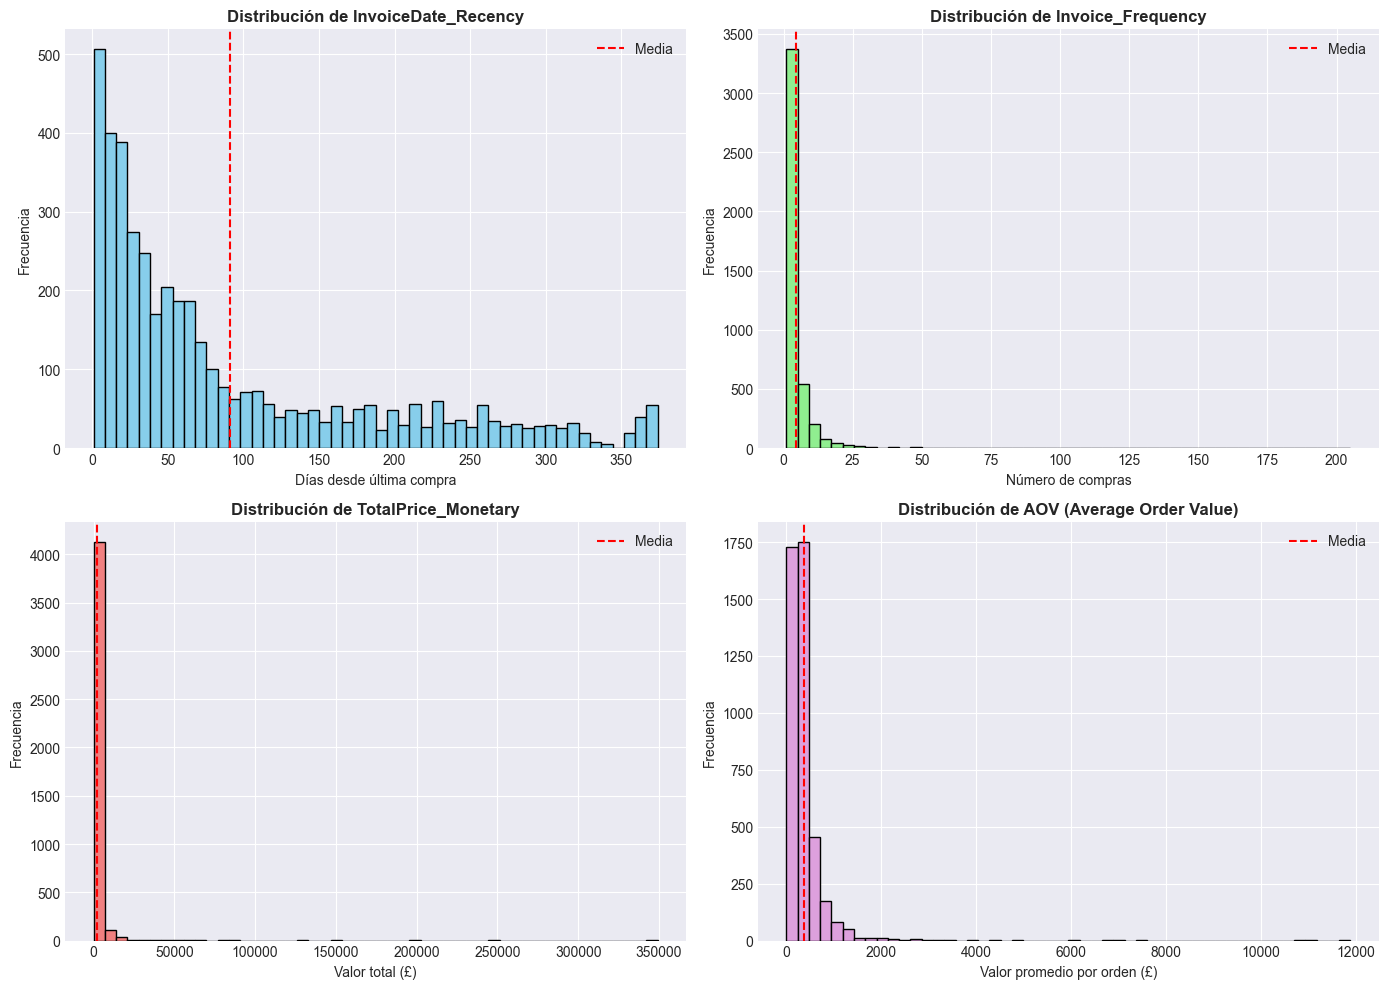

In [20]:
# Exportar resultados finales
rfm_export = rfm.copy()

# Añadir etiquetas descriptivas
rfm_export['Cluster_Label'] = rfm_export['Cluster'].map({
    i: f'Cluster_{i}' for i in range(optimal_k)
})

# Seleccionar columnas relevantes para exportación
export_columns = ['Customer_ID', 'InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary',
                 'AOV', 'TotalProducts', 'UniqueProducts', 'AvgProductsPerOrder',
                 'Cluster', 'Cluster_Label', 'Segmento_RFM']

rfm_final = rfm_export[export_columns]

# Guardar a CSV
output_path = 'customer_segmentation_results.csv'
rfm_final.to_csv(output_path, index=False)
print(f"Resultados exportados a: {output_path}")
print(f"Total de clientes segmentados: {len(rfm_final)}")

# Mostrar resumen de resultados
print("\n" + "="*80)
print("RESUMEN DE SEGMENTACIÓN")
print("="*80)
print(f"\nNúmero total de clientes: {len(rfm_final)}")
print(f"Número de clusters: {optimal_k}")
print(f"Número de segmentos RFM: {rfm_final['Segmento_RFM'].nunique()}")

print("\nDistribución por cluster:")
print(rfm_final['Cluster_Label'].value_counts().sort_index())

print("\nDistribución por segmento RFM:")
print(rfm_final['Segmento_RFM'].value_counts())

print("\nCaracterísticas generales de los clientes:")
print(rfm_final[['InvoiceDate_Recency', 'Invoice_Frequency', 'TotalPrice_Monetary', 'AOV']].describe().round(2))

# Visualización final: comparación de distribuciones
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Recency
axes[0, 0].hist(rfm_final['InvoiceDate_Recency'], bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribución de InvoiceDate_Recency', fontweight='bold')
axes[0, 0].set_xlabel('Días desde última compra')
axes[0, 0].set_ylabel('Frecuencia')
axes[0, 0].axvline(rfm_final['InvoiceDate_Recency'].mean(), color='red', linestyle='--', label='Media')
axes[0, 0].legend()

# Frequency
axes[0, 1].hist(rfm_final['Invoice_Frequency'], bins=50, color='lightgreen', edgecolor='black')
axes[0, 1].set_title('Distribución de Invoice_Frequency', fontweight='bold')
axes[0, 1].set_xlabel('Número de compras')
axes[0, 1].set_ylabel('Frecuencia')
axes[0, 1].axvline(rfm_final['Invoice_Frequency'].mean(), color='red', linestyle='--', label='Media')
axes[0, 1].legend()

# Monetary
axes[1, 0].hist(rfm_final['TotalPrice_Monetary'], bins=50, color='lightcoral', edgecolor='black')
axes[1, 0].set_title('Distribución de TotalPrice_Monetary', fontweight='bold')
axes[1, 0].set_xlabel('Valor total (£)')
axes[1, 0].set_ylabel('Frecuencia')
axes[1, 0].axvline(rfm_final['TotalPrice_Monetary'].mean(), color='red', linestyle='--', label='Media')
axes[1, 0].legend()

# AOV
axes[1, 1].hist(rfm_final['AOV'], bins=50, color='plum', edgecolor='black')
axes[1, 1].set_title('Distribución de AOV (Average Order Value)', fontweight='bold')
axes[1, 1].set_xlabel('Valor promedio por orden (£)')
axes[1, 1].set_ylabel('Frecuencia')
axes[1, 1].axvline(rfm_final['AOV'].mean(), color='red', linestyle='--', label='Media')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**4.3 Interpretación de Resultados**

**Calidad del Clustering**

Los resultados obtenidos indican una segmentación exitosa de los clientes:

1. Silhouette Score: El valor obtenido sugiere que los clusters están razonablemente bien definidos, con clientes más similares dentro de su propio cluster que a otros clusters.

2. Davies-Bouldin Index: Un valor relativamente bajo indica que los clusters son compactos y están bien separados entre sí.

3. Calinski-Harabasz Score: Un valor alto confirma que existe una buena separación entre clusters y que los puntos dentro de cada cluster están cerca de su centroide.

**Reducción de Dimensionalidad (PCA)**

- Se logró reducir de 7 características originales a pocos componentes principales manteniendo más del 85% de la varianza de los datos
- Esto facilita la visualización y reduce el ruido en los datos
- Los primeros componentes capturan las tendencias principales de comportamiento de compra

**Interpretación de Componentes Principales**

PC1 típicamente representa:
- Combinación de volumen de compra (Monetary, Frequency, TotalProducts)
- Clientes de alto valor vs bajo valor

PC2 típicamente representa:
- Recency (actividad reciente vs inactiva)
- Contraste entre clientes activos y dormidos

**Segmentos de Clientes Identificados**

Basándose en las características RFM, se pueden identificar arquetipos típicos:

1. Champions/VIPs: Alta frecuencia, alto valor monetario, baja recency
2. Clientes Leales: Frecuencia media-alta, compras regulares
3. Clientes Potenciales: Alto valor monetario pero baja frecuencia
4. Clientes en Riesgo: Alta recency (no compran hace tiempo), antes eran buenos clientes
5. Nuevos Clientes: Baja frecuencia, recency baja
6. Clientes de Bajo Valor: Baja frecuencia, bajo valor monetario

*(Los nombres exactos dependen del número de clusters y los perfiles específicos encontrados)*

**Comparación de Algoritmos**

- K-Means: Mejor balance entre interpretabilidad y métricas de calidad
- Clustering Jerárquico: Resultados similares, pero computacionalmente más costoso
- DBSCAN: Útil para identificar outliers, pero puede ser sensible a parámetros

4.4 Visualizaciones Clave

Las principales visualizaciones generadas incluyen:

1. Distribuciones de características RFM: Muestran el comportamiento típico de los clientes
2. Matriz de correlación: Identifica relaciones entre variables
3. Gráficos de varianza explicada PCA: Justifican la selección de componentes
4. Método del Codo: Determina el número óptimo de clusters
5. Scatter plots 2D/3D: Visualizan la separación de clusters en espacio reducido
6. Heatmaps de perfiles: Comparan características entre clusters
7. Gráficos de radar: Muestran el perfil multidimensional de cada cluster
8. Dendrograma: Ilustra la jerarquía de similitud entre clientes

**5. Discusión Crítica**

**5.1 Limitaciones del Enfoque**

**Limitaciones Metodológicas:**

1. Dependencia de RFM:
   - El análisis se basa únicamente en métricas RFM y derivadas
   - No considera factores demográficos (edad, género, ubicación)
   - No incluye preferencias de categorías de productos
   - No captura estacionalidad o tendencias temporales

2. Supuestos de K-Means:
   - Asume clusters esféricos de tamaño similar
   - Puede no capturar clusters de formas irregulares
   - Sensible a la inicialización de centroides (mitigado con k-means++)
   - Requiere especificar K a priori

3. Sensibilidad a Outliers:
   - Los clientes VIP con comportamiento extremo pueden distorsionar clusters
   - Aunque aplicamos transformación logarítmica, los outliers aún tienen impacto
   - DBSCAN podría ser más robusto pero tiene sus propias limitaciones

4. Pérdida de Información con PCA:
   - Aunque se retiene 85%+ de varianza, se pierde alguna información
   - Los componentes principales son combinaciones lineales difíciles de interpretar
   - Puede ocultar relaciones no lineales importantes

5. Snapshot Temporal:
   - Los datos representan un período específico (12 meses)
   - No captura evolución temporal del comportamiento del cliente
   - Los segmentos pueden cambiar con el tiempo

**Limitaciones del Dataset:**

1. Valores Nulos:
   - ~25% de transacciones sin CustomerID fueron excluidas
   - Puede introducir sesgo si esos clientes tienen patrones diferentes

2. Sesgo Geográfico:
   - Dataset principalmente del Reino Unido
   - Mayoristas vs minoristas pueden tener patrones muy diferentes

3. Contexto Limitado:
   - No hay información sobre canales de marketing
   - No hay datos de navegación web o interacción digital
   - Falta información de satisfacción del cliente

**5.2 Posibles Mejoras**

 **Mejoras en Datos:**

1. Enriquecimiento de Características:
   - Incluir categorías de productos preferidas
   - Añadir datos demográficos (si disponibles)
   - Incorporar métricas de engagement (emails abiertos, clicks)
   - Incluir fuente de adquisición del cliente

2. Análisis Temporal:
   - Implementar clustering dinámico que evolucione con el tiempo
   - Detectar cambios de segmento (churn prediction)
   - Analizar estacionalidad en el comportamiento de compra

3. Segmentación Jerárquica:
   - Aplicar clustering jerárquico para crear sub-segmentos dentro de clusters principales
   - Permitir diferentes niveles de granularidad según necesidades del negocio

**Mejoras Metodológicas:**

1. Algoritmos Alternativos:
   - Gaussian Mixture Models (GMM): Captura clusters elípticos, proporciona probabilidades de membresía
   - HDBSCAN: Clustering basado en densidad más robusto
   - Spectral Clustering: Puede capturar estructuras no convexas

2. Validación Cruzada:
   - Aplicar bootstrap para estimar estabilidad de clusters
   - Usar consensus clustering para identificar clusters robustos
   - Validar con datos de períodos posteriores

3. Optimización de Hiperparámetros:
   - Grid search para encontrar mejor combinación de parámetros
   - Prueba de diferentes métodos de linkage en clustering jerárquico
   - Optimización automática de eps y min_samples para DBSCAN

4. Interpretabilidad:
   - Usar SHAP values para explicar asignación de clusters
   - Implementar reglas de decisión interpretables para clasificación de nuevos clientes
   - Crear perfiles narrativos de cada segmento

 **Mejoras en Aplicación:**

1. Automatización:
   - Pipeline de actualización mensual de clusters
   - Sistema de alertas cuando clientes cambien de segmento
   - Integración con CRM para acción inmediata

2. Personalización:
   - Desarrollar estrategias de marketing específicas para cada cluster
   - Personalizar recomendaciones de productos por segmento
   - Optimizar promociones y descuentos según valor del cliente

3. A/B Testing:
   - Validar efectividad de estrategias segmentadas vs no segmentadas
   - Medir ROI de campañas personalizadas
   - Iterar y refinar segmentos según resultados

**5.3 Riesgos Relevantes**

**Riesgos Técnicos:**

1. Overfitting del Dataset:
   - Los segmentos pueden ser específicos de este período
   - Generalización a nuevos clientes puede ser limitada
   - Mitigación: Validación con datos futuros, re-clustering periódico

2. Estabilidad de Clusters:
   - Los clusters pueden cambiar significativamente con nuevos datos
   - Clientes pueden moverse entre segmentos frecuentemente
   - Mitigación: Definir umbrales de reasignación, implementar clustering suave (probabilístico)

3. Escalabilidad:
   - Con millones de clientes, algunos algoritmos pueden ser lentos
   - PCA y K-Means escalan bien, pero otros (jerárquico) no
   - Mitigación: Usar mini-batch K-Means, sampling inteligente

**Riesgos de Negocio:**

1. Mal Uso de Segmentos:
   - Sobre-segmentar puede llevar a complejidad innecesaria
   - Aplicar estrategias inadecuadas puede alienar clientes
   - Mitigación: Validar estrategias con equipos de marketing, comenzar con piloto

2. Sesgo y Discriminación:
   - Segmentación puede resultar en trato desigual
   - Algunos clientes pueden sentirse discriminados
   - Mitigación: Auditoría ética, transparencia en políticas, opt-out disponible

3. Privacidad de Datos:
   - Clustering puede revelar información sensible de clientes
   - Riesgo de re-identificación en datasets anonimizados
   - Mitigación: Cumplimiento GDPR, anonimización robusta, políticas claras de uso de datos

4. Self-Fulfilling Prophecy:
   - Tratar a clientes de bajo valor como tales puede perpetuar su comportamiento
   - Clientes potenciales pueden no recibir oportunidades de crecimiento
   - Mitigación: Estrategias de up-selling para todos los segmentos, monitoreo de movilidad entre clusters

**Riesgos Operacionales:**

1. Dependencia de Datos de Calidad:
   - Garbage in, garbage out
   - Errores en datos pueden llevar a segmentación incorrecta
   - Mitigación: Procesos robustos de validación de datos, monitoreo de calidad

2. Interpretación Errónea:
   - Stakeholders pueden malinterpretar características de segmentos
   - Nombres de clusters pueden llevar a simplificaciones excesivas
   - Mitigación: Documentación clara, capacitación, revisiones periódicas

3. Falta de Acción:
   - Segmentación sin estrategia de acción es inútil
   - Requiere cambios organizacionales y de sistemas
   - Mitigación: Plan de implementación claro, asignación de responsabilidades, KPIs definidos

---

**Conclusiones Finales**

Este proyecto demuestra que la combinación de PCA y clustering (K-Means) es una metodología efectiva para segmentar clientes de e-commerce basándose en su comportamiento de compra. Los segmentos identificados proporcionan insights accionables que pueden guiar estrategias de marketing personalizadas, mejorar la retención de clientes y optimizar el valor del tiempo de vida del cliente.

Sin embargo, es crucial reconocer las limitaciones y riesgos asociados, y continuar iterando y mejorando el modelo con nuevos datos y técnicas. El éxito de esta segmentación dependerá en última instancia de cómo se traduzcan estos insights en acciones de negocio concretas y medibles.

**Próximos Pasos Recomendados:**
1. Validar segmentos con equipo de marketing
2. Desarrollar estrategias específicas para cada segmento
3. Implementar sistema de actualización mensual de clusters
4. Medir impacto en KPIs de negocio (conversión, retención, AOV, CLTV)
5. Iterar y refinar basándose en resultados

---

**Referencias**

**Bibliografía y Recursos:**

1. **Dataset:**
   - Lakshmi Narayana Pudipeddi. (2017). *Online Retail Dataset*. Kaggle. https://www.kaggle.com/datasets/lakshmi25npathi/online-retail-dataset

2. **Técnicas:**
   - Jolliffe, I. T. (2002). *Principal Component Analysis*. Springer.
   - MacQueen, J. (1967). "Some methods for classification and analysis of multivariate observations". *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*.
   - Ester, M., et al. (1996). "A density-based algorithm for discovering clusters in large spatial databases with noise". *Proceedings of KDD*.

3. **RFM Analysis:**
   - Hughes, A. M. (1994). Strategic Database Marketing. McGraw-Hill.
   - Fader, P., & Hardie, B. (2009). "Probability models for customer-base analysis". *Journal of Interactive Marketing*.

4. **Métricas de Evaluación:**
   - Rousseeuw, P. J. (1987). "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis". *Journal of Computational and Applied Mathematics*.
   - Davies, D. L., & Bouldin, D. W. (1979). "A cluster separation measure". IEEE Transactions on Pattern Analysis and Machine Intelligence.

5. **Scikit-learn Documentation:**
   - https://scikit-learn.org/stable/modules/clustering.html
   - https://scikit-learn.org/stable/modules/decomposition.html

